# Pan-atlas resource inspection

**Purpose.** Inspect the public atlas resources used for pan-atlas enrichment work, without loading prediction models or performance thresholds.

The notebook answers four questions:

1. Which external atlas resources are included?
2. What does each resource contain biologically and technically?
3. How many genes, identifiers, groups, and memberships are present after normalization?
4. How redundant or complementary are the resources before any model-performance analysis?

The normalized long format used throughout is:

```text
source, collection, group_name, gene_symbol, uniprot_id, ensembl_id, evidence, raw_value
```

No model output, Pearson threshold, cosine threshold, or MSE threshold is required.


## 1. Resource references and scope

The table below documents the resources inspected by this notebook.

| Resource | Main content | Local file expected | Primary reference / documentation |
|---|---|---|---|
| Human Protein Atlas (HPA) | Human gene/protein annotations, protein classes, tissue and cell context, subcellular resource downloads | `hpa_proteinatlas.tsv.zip`, `hpa_subcellular_location.tsv.zip` | Human Protein Atlas downloadable data and release documentation; Uhlen et al., *Science* 2015; HPA versioned releases |
| UniProtKB Human | Protein accessions, gene names, keywords, GO annotations, subcellular-location comments | `uniprot_human.tsv.gz` | UniProt Consortium, *Nucleic Acids Research* 2025 |
| Gene Ontology Annotation / GOA Human | GO annotations for human gene products, with evidence codes and ontology aspect | `goa_human.gaf.gz`; optional `go-basic.obo` for GO names | Gene Ontology Consortium, *Nucleic Acids Research* 2026; GO annotation downloads |
| Reactome | Manually curated biological pathways represented as gene sets | `reactome_pathways.gmt.zip` | Reactome Pathway Knowledgebase 2024, *Nucleic Acids Research* |
| WikiPathways | Community-curated pathway gene sets, Homo sapiens GMT when available | `wikipathways_human.gmt` | WikiPathways 2024, *Nucleic Acids Research* |

The inspection code keeps resource provenance visible: raw files remain in `pan_atlas_downloads/`, a zip bundle can be produced for reproducibility, and summary tables are written to `pan_atlas_resource_inspection_outputs/tables/`.


In [1]:
# 2. Setup

from pathlib import Path
from collections import defaultdict
import datetime as _dt
import gzip
import io
import json
import math
import os
import re
import shutil
import textwrap
import urllib.parse
import urllib.request
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda x: x

BASE_DIR = Path.cwd()
DOWNLOAD_DIR = BASE_DIR / "pan_atlas_downloads"
OUTPUT_DIR = BASE_DIR / "pan_atlas_resource_inspection_outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
PLOTS_DIR = OUTPUT_DIR / "plots"
RESOURCE_ZIP = BASE_DIR / "pan_atlas_resources.zip"

for d in [DOWNLOAD_DIR, OUTPUT_DIR, TABLES_DIR, PLOTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Set to False when all expected resource files are already present locally.
RUN_DOWNLOADS = True
OVERWRITE_DOWNLOADS = False

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 240,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Base directory: {BASE_DIR.resolve()}")
print(f"Download directory: {DOWNLOAD_DIR.resolve()}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Base directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Download directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_downloads
Output directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs


In [2]:
# 3. Resource catalogue

RESOURCE_CATALOGUE = [
    {
        "resource": "Human Protein Atlas",
        "short_name": "hpa_proteinatlas.tsv.zip",
        "source": "HPA",
        "collection": "protein_class",
        "url": "https://www.proteinatlas.org/download/proteinatlas.tsv.zip",
        "format": "zipped TSV",
        "contains": "Protein-centric HPA table. This notebook primarily extracts the Protein class field for atlas groups.",
        "reference": "Human Protein Atlas downloadable data; Uhlen et al., Science 2015; HPA release documentation.",
    },
    {
        "resource": "Human Protein Atlas subcellular location",
        "short_name": "hpa_subcellular_location.tsv.zip",
        "source": "HPA",
        "collection": "subcellular_location",
        "url": "https://www.proteinatlas.org/download/subcellular_location.tsv.zip",
        "format": "zipped TSV",
        "contains": "Subcellular localization annotations from HPA.",
        "reference": "Human Protein Atlas subcellular resource documentation.",
    },
    {
        "resource": "UniProtKB Human",
        "short_name": "uniprot_human.tsv.gz",
        "source": "UniProtKB",
        "collection": "keywords_go_subcellular",
        "url": "https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=tsv&query=%28organism_id%3A9606%29&fields=accession%2Cgene_primary%2Cgene_names%2Cprotein_name%2Ckeyword%2Cgo_id%2Cgo_p%2Cgo_f%2Cgo_c%2Ccc_subcellular_location",
        "format": "gzipped TSV from UniProt REST stream",
        "contains": "Human UniProtKB entries with accessions, gene names, keywords, GO names, and subcellular-location comments.",
        "reference": "UniProt Consortium, UniProt: the Universal Protein Knowledgebase in 2025, Nucleic Acids Research.",
    },
    {
        "resource": "GOA Human annotations",
        "short_name": "goa_human.gaf.gz",
        "source": "GOA",
        "collection": "go_annotations",
        "url": "https://current.geneontology.org/annotations/goa_human.gaf.gz",
        "format": "gzipped GAF 2.x",
        "contains": "Human GO annotations with GO ID, ontology aspect, evidence code, and gene-product identifier.",
        "reference": "Gene Ontology Consortium annotation downloads and NAR Gene Ontology knowledgebase publication.",
    },
    {
        "resource": "Gene Ontology names",
        "short_name": "go-basic.obo",
        "source": "GO",
        "collection": "ontology_names",
        "url": "https://current.geneontology.org/ontology/go-basic.obo",
        "format": "OBO ontology file",
        "contains": "Optional GO ID to term-name and namespace mapping used to make GOA groups interpretable.",
        "reference": "Gene Ontology Consortium ontology downloads.",
    },
    {
        "resource": "Reactome pathways",
        "short_name": "reactome_pathways.gmt.zip",
        "source": "Reactome",
        "collection": "pathways",
        "url": "https://reactome.org/download/current/ReactomePathways.gmt.zip",
        "format": "zipped GMT",
        "contains": "Reactome pathway gene sets. Human-specific GMT content is preferred when present.",
        "reference": "Reactome Pathway Knowledgebase 2024, Nucleic Acids Research.",
    },
    {
        "resource": "WikiPathways Homo sapiens pathways",
        "short_name": "wikipathways_human.gmt",
        "source": "WikiPathways",
        "collection": "pathways",
        "url": "auto-discovered from https://data.wikipathways.org/current/gmt/ or https://wikipathways-data.wmcloud.org/current/gmt/",
        "format": "GMT",
        "contains": "Homo sapiens WikiPathways gene sets, when a current GMT file is available.",
        "reference": "WikiPathways 2024: next generation pathway database, Nucleic Acids Research.",
    },
]

resource_catalogue = pd.DataFrame(RESOURCE_CATALOGUE)
display(resource_catalogue[["resource", "source", "collection", "short_name", "format", "contains", "reference"]])
resource_catalogue.to_csv(TABLES_DIR / "resource_catalogue.csv", index=False)


,resource,source,collection,short_name,format,contains,reference
0,Human Protein Atlas,HPA,protein_class,hpa_proteinatlas.tsv.zip,zipped TSV,Protein-centric HPA table. This notebook prima...,Human Protein Atlas downloadable data; Uhlen e...
1,Human Protein Atlas subcellular location,HPA,subcellular_location,hpa_subcellular_location.tsv.zip,zipped TSV,Subcellular localization annotations from HPA.,Human Protein Atlas subcellular resource docum...
2,UniProtKB Human,UniProtKB,keywords_go_subcellular,uniprot_human.tsv.gz,gzipped TSV from UniProt REST stream,"Human UniProtKB entries with accessions, gene ...","UniProt Consortium, UniProt: the Universal Pro..."
3,GOA Human annotations,GOA,go_annotations,goa_human.gaf.gz,gzipped GAF 2.x,"Human GO annotations with GO ID, ontology aspe...",Gene Ontology Consortium annotation downloads ...
4,Gene Ontology names,GO,ontology_names,go-basic.obo,OBO ontology file,Optional GO ID to term-name and namespace mapp...,Gene Ontology Consortium ontology downloads.
5,Reactome pathways,Reactome,pathways,reactome_pathways.gmt.zip,zipped GMT,Reactome pathway gene sets. Human-specific GMT...,"Reactome Pathway Knowledgebase 2024, Nucleic A..."
6,WikiPathways Homo sapiens pathways,WikiPathways,pathways,wikipathways_human.gmt,GMT,"Homo sapiens WikiPathways gene sets, when a cu...",WikiPathways 2024: next generation pathway dat...


In [3]:
# 4. Download or reuse local resource files

UNIPROT_HUMAN_URL = (
    "https://rest.uniprot.org/uniprotkb/stream?"
    + urllib.parse.urlencode({
        "compressed": "true",
        "format": "tsv",
        "query": "(organism_id:9606)",
        "fields": "accession,gene_primary,gene_names,protein_name,keyword,go_id,go_p,go_f,go_c,cc_subcellular_location",
    })
)

RESOURCE_URLS = {
    "hpa_proteinatlas.tsv.zip": "https://www.proteinatlas.org/download/proteinatlas.tsv.zip",
    "hpa_subcellular_location.tsv.zip": "https://www.proteinatlas.org/download/subcellular_location.tsv.zip",
    "uniprot_human.tsv.gz": UNIPROT_HUMAN_URL,
    "goa_human.gaf.gz": "https://current.geneontology.org/annotations/goa_human.gaf.gz",
    "go-basic.obo": "https://current.geneontology.org/ontology/go-basic.obo",
    "reactome_pathways.gmt.zip": "https://reactome.org/download/current/ReactomePathways.gmt.zip",
}


def extract_resource_zip_if_needed():
    if RESOURCE_ZIP.exists() and not any(DOWNLOAD_DIR.glob("*")):
        print(f"Extracting local resource bundle: {RESOURCE_ZIP.name}")
        with zipfile.ZipFile(RESOURCE_ZIP) as z:
            z.extractall(DOWNLOAD_DIR)


def download_file(url, out_path, overwrite=False, timeout=180):
    out_path = Path(out_path)
    if out_path.exists() and out_path.stat().st_size > 0 and not overwrite:
        print(f"Already exists: {out_path.name}")
        return True
    try:
        print(f"Downloading {out_path.name} ...")
        with urllib.request.urlopen(url, timeout=timeout) as r, open(out_path, "wb") as f:
            shutil.copyfileobj(r, f)
        print(f"Downloaded {out_path.name}: {out_path.stat().st_size / 1e6:.2f} MB")
        return True
    except Exception as e:
        print(f"Skipped {out_path.name}: {e}")
        return False


def find_current_wikipathways_human_gmt():
    directories = [
        "https://data.wikipathways.org/current/gmt/",
        "https://wikipathways-data.wmcloud.org/current/gmt/",
    ]
    patterns = [
        r'href=["\']([^"\']*Homo_sapiens[^"\']*\.gmt)["\']',
        r'(wikipathways-[^\s"\']*gmt-Homo_sapiens\.gmt)',
    ]
    for base_url in directories:
        try:
            with urllib.request.urlopen(base_url, timeout=30) as r:
                html = r.read().decode("utf-8", errors="ignore")
            matches = []
            for pattern in patterns:
                matches.extend(re.findall(pattern, html))
            if matches:
                filename = sorted(set(matches))[-1]
                return urllib.parse.urljoin(base_url, filename)
        except Exception:
            continue
    return None

extract_resource_zip_if_needed()

download_status = {}
if RUN_DOWNLOADS:
    for fname, url in RESOURCE_URLS.items():
        download_status[fname] = download_file(url, DOWNLOAD_DIR / fname, overwrite=OVERWRITE_DOWNLOADS)

    wp_url = find_current_wikipathways_human_gmt()
    if wp_url:
        download_status["wikipathways_human.gmt"] = download_file(
            wp_url, DOWNLOAD_DIR / "wikipathways_human.gmt", overwrite=OVERWRITE_DOWNLOADS
        )
    else:
        print("WikiPathways Homo sapiens GMT could not be auto-discovered; local file will be used if present.")
        download_status["wikipathways_human.gmt"] = (DOWNLOAD_DIR / "wikipathways_human.gmt").exists()
else:
    download_status = {p.name: p.exists() and p.stat().st_size > 0 for p in DOWNLOAD_DIR.glob("*") if p.is_file()}

# Bundle available files for reproducibility.
with zipfile.ZipFile(RESOURCE_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(DOWNLOAD_DIR.glob("*")):
        if f.is_file() and f.stat().st_size > 0:
            z.write(f, arcname=f.name)

status_df = pd.DataFrame(
    [{"file": k, "available": bool(v)} for k, v in sorted(download_status.items())]
)
if not status_df.empty:
    display(status_df)
    status_df.to_csv(TABLES_DIR / "download_status.csv", index=False)
print(f"Resource bundle path: {RESOURCE_ZIP.resolve()}")


Already exists: hpa_proteinatlas.tsv.zip
Skipped hpa_subcellular_location.tsv.zip: HTTP Error 404: Not Found
Already exists: uniprot_human.tsv.gz
Skipped goa_human.gaf.gz: HTTP Error 403: Forbidden
Skipped go-basic.obo: HTTP Error 403: Forbidden
Already exists: reactome_pathways.gmt.zip
Already exists: wikipathways_human.gmt


,file,available
0,go-basic.obo,False
1,goa_human.gaf.gz,False
2,hpa_proteinatlas.tsv.zip,True
3,hpa_subcellular_location.tsv.zip,False
4,reactome_pathways.gmt.zip,True
5,uniprot_human.tsv.gz,True
6,wikipathways_human.gmt,True


Resource bundle path: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resources.zip


In [4]:
# 5. File inventory and raw table column inspection


def human_size(n):
    if n is None or pd.isna(n):
        return ""
    units = ["B", "KB", "MB", "GB"]
    n = float(n)
    for unit in units:
        if n < 1024 or unit == units[-1]:
            return f"{n:.1f} {unit}"
        n /= 1024


def inspect_file(path):
    path = Path(path)
    if not path.exists():
        return {"file": path.name, "exists": False}
    out = {
        "file": path.name,
        "exists": True,
        "size_bytes": path.stat().st_size,
        "size": human_size(path.stat().st_size),
        "modified": _dt.datetime.fromtimestamp(path.stat().st_mtime).isoformat(timespec="seconds"),
    }
    return out

expected_files = [r["short_name"] for r in RESOURCE_CATALOGUE]
file_inventory = pd.DataFrame([inspect_file(DOWNLOAD_DIR / f) for f in expected_files])
display(file_inventory)
file_inventory.to_csv(TABLES_DIR / "file_inventory.csv", index=False)


def preview_tsv(path, compression=None, zip_inner=None, nrows=5):
    path = Path(path)
    if not path.exists():
        return None
    try:
        if zip_inner:
            with zipfile.ZipFile(path) as z:
                names = [n for n in z.namelist() if not n.endswith("/")]
                target = zip_inner if zip_inner in names else names[0]
                return pd.read_csv(z.open(target), sep="\t", nrows=nrows)
        if compression == "gzip" or path.suffix == ".gz":
            return pd.read_csv(path, sep="\t", compression="gzip", nrows=nrows, comment="!")
        return pd.read_csv(path, sep="\t", nrows=nrows)
    except Exception as e:
        print(f"Could not preview {path.name}: {e}")
        return None

raw_previews = {}
for fname in ["hpa_proteinatlas.tsv.zip", "hpa_subcellular_location.tsv.zip"]:
    raw_previews[fname] = preview_tsv(DOWNLOAD_DIR / fname, zip_inner=True, nrows=3)
raw_previews["uniprot_human.tsv.gz"] = preview_tsv(DOWNLOAD_DIR / "uniprot_human.tsv.gz", compression="gzip", nrows=3)

column_rows = []
for fname, df in raw_previews.items():
    if df is not None:
        for i, col in enumerate(df.columns, start=1):
            example = df[col].dropna().astype(str).head(1)
            column_rows.append({"file": fname, "column_index": i, "column": col, "example_value": example.iloc[0] if len(example) else ""})
raw_column_inventory = pd.DataFrame(column_rows)
if not raw_column_inventory.empty:
    display(raw_column_inventory)
    raw_column_inventory.to_csv(TABLES_DIR / "raw_column_inventory.csv", index=False)
else:
    print("No raw TSV previews available yet.")


,file,exists,size_bytes,size,modified
0,hpa_proteinatlas.tsv.zip,True,7460135.0,7.1 MB,2026-06-09T19:18:37
1,hpa_subcellular_location.tsv.zip,False,NaN,NaN,NaN
2,uniprot_human.tsv.gz,True,12642187.0,12.1 MB,2026-06-09T19:20:23
3,goa_human.gaf.gz,False,NaN,NaN,NaN
4,go-basic.obo,False,NaN,NaN,NaN
5,reactome_pathways.gmt.zip,True,294237.0,287.3 KB,2026-06-09T19:18:40
6,wikipathways_human.gmt,True,340454.0,332.5 KB,2026-06-09T19:20:27


,file,column_index,column,example_value
0,hpa_proteinatlas.tsv.zip,1,Gene,TSPAN6
1,hpa_proteinatlas.tsv.zip,2,Gene synonym,"T245, TM4SF6, TSPAN-6"
2,hpa_proteinatlas.tsv.zip,3,Ensembl,ENSG00000000003
3,hpa_proteinatlas.tsv.zip,4,Gene description,Tetraspanin 6
4,hpa_proteinatlas.tsv.zip,5,Uniprot,O43657
...,...,...,...,...
124,uniprot_human.tsv.gz,6,Gene Ontology IDs,GO:0004722; GO:0004725; GO:0005737; GO:0006629...
125,uniprot_human.tsv.gz,7,Gene Ontology (biological process),apoptotic process [GO:0006915]; lipid metaboli...
126,uniprot_human.tsv.gz,8,Gene Ontology (molecular function),enzyme binding [GO:0019899]; phosphatidylinosi...
127,uniprot_human.tsv.gz,9,Gene Ontology (cellular component),cytoplasm [GO:0005737]; dendritic spine [GO:00...


In [5]:
# 6. Helpers for normalization and parsing


def clean_gene_symbol(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if not x or x.lower() in {"nan", "none", "na", "null"}:
        return np.nan
    return x.split()[0].upper()


def clean_identifier(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if not x or x.lower() in {"nan", "none", "na", "null"}:
        return np.nan
    return x


def normalize_group_name(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    x = re.sub(r"\s+", " ", x)
    if not x or x.lower() in {"nan", "none", "na", "null", "unknown"}:
        return np.nan
    return x


def split_multi_value(x, seps=(";", ",")):
    if pd.isna(x):
        return []
    x = str(x).strip()
    if not x or x.lower() in {"nan", "none", "na", "null"}:
        return []
    pattern = "|".join(map(re.escape, seps))
    vals = [normalize_group_name(v) for v in re.split(pattern, x)]
    return [v for v in vals if pd.notna(v)]


def first_existing_col(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c in df.columns:
            return c
        if c.lower() in lower:
            return lower[c.lower()]
    if required:
        raise KeyError(f"None of the candidate columns were found: {candidates}")
    return None


def add_atlas_frame(frames, df, source, collection, evidence_col=None, raw_value_col=None):
    expected = ["source", "collection", "group_name", "gene_symbol", "uniprot_id", "ensembl_id", "evidence", "raw_value"]
    out = df.copy()
    out["source"] = source
    out["collection"] = collection
    for col in ["group_name", "gene_symbol", "uniprot_id", "ensembl_id"]:
        if col not in out.columns:
            out[col] = np.nan
    out["evidence"] = out[evidence_col] if evidence_col and evidence_col in out.columns else np.nan
    out["raw_value"] = out[raw_value_col] if raw_value_col and raw_value_col in out.columns else out["group_name"]
    out = out[expected]
    out["group_name"] = out["group_name"].map(normalize_group_name)
    out["gene_symbol"] = out["gene_symbol"].map(clean_gene_symbol)
    out["uniprot_id"] = out["uniprot_id"].map(clean_identifier)
    out["ensembl_id"] = out["ensembl_id"].map(clean_identifier)
    out["evidence"] = out["evidence"].map(clean_identifier)
    out["raw_value"] = out["raw_value"].map(normalize_group_name)
    out = out.dropna(subset=["group_name"])
    out = out.loc[out["gene_symbol"].notna() | out["uniprot_id"].notna() | out["ensembl_id"].notna()]
    out = out.drop_duplicates()
    if not out.empty:
        frames.append(out)
        print(f"Added {source} / {collection}: {out.shape[0]:,} memberships, {out['group_name'].nunique():,} groups, {out['gene_symbol'].nunique():,} genes")
    else:
        print(f"No rows added for {source} / {collection}")


In [6]:
# 7. GO ontology name mapping


def parse_go_obo(path):
    path = Path(path)
    if not path.exists():
        print("GO OBO file not available; GOA groups will use GO IDs only.")
        return {}
    mapping = {}
    current = {}
    with open(path, "rt", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.rstrip("\n")
            if line == "[Term]":
                if current.get("id") and not current.get("is_obsolete"):
                    mapping[current["id"]] = {
                        "name": current.get("name", current["id"]),
                        "namespace": current.get("namespace", "GO"),
                    }
                current = {}
            elif line.startswith("id: "):
                current["id"] = line[4:].strip()
            elif line.startswith("name: "):
                current["name"] = line[6:].strip()
            elif line.startswith("namespace: "):
                current["namespace"] = line[11:].strip()
            elif line.startswith("is_obsolete: true"):
                current["is_obsolete"] = True
    if current.get("id") and not current.get("is_obsolete"):
        mapping[current["id"]] = {
            "name": current.get("name", current["id"]),
            "namespace": current.get("namespace", "GO"),
        }
    print(f"GO names loaded: {len(mapping):,} active terms")
    return mapping

GO_TERM_MAP = parse_go_obo(DOWNLOAD_DIR / "go-basic.obo")


GO OBO file not available; GOA groups will use GO IDs only.


In [7]:
# 8. Parsers for each atlas resource

atlas_frames = []
raw_table_notes = []


def parse_hpa_proteinatlas(path):
    path = Path(path)
    if not path.exists():
        print("HPA main file missing.")
        return
    with zipfile.ZipFile(path) as z:
        names = [n for n in z.namelist() if not n.endswith("/")]
        name = names[0]
        hpa = pd.read_csv(z.open(name), sep="\t", low_memory=False)
    raw_table_notes.append({"source": "HPA", "collection": "raw_proteinatlas", "rows": len(hpa), "columns": len(hpa.columns), "file": path.name})
    gene_col = first_existing_col(hpa, ["Gene", "gene"], required=True)
    ens_col = first_existing_col(hpa, ["Ensembl", "ensembl"], required=False)
    uni_col = first_existing_col(hpa, ["Uniprot", "UniProt", "uniprot"], required=False)
    class_col = first_existing_col(hpa, ["Protein class", "protein_class"], required=False)
    if not class_col:
        print("HPA Protein class column not found.")
        return
    rows = []
    for _, r in hpa.iterrows():
        gene = r.get(gene_col)
        ens = r.get(ens_col) if ens_col else np.nan
        uni = r.get(uni_col) if uni_col else np.nan
        for cls in split_multi_value(r.get(class_col), seps=(";", ",")):
            rows.append({"gene_symbol": gene, "ensembl_id": ens, "uniprot_id": uni, "group_name": cls, "raw_value": r.get(class_col)})
    add_atlas_frame(atlas_frames, pd.DataFrame(rows), "HPA", "protein_class", raw_value_col="raw_value")


def parse_hpa_subcellular(path):
    path = Path(path)
    if not path.exists():
        print("HPA subcellular file missing.")
        return
    try:
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if not n.endswith("/")]
            name = names[0]
            sub = pd.read_csv(z.open(name), sep="\t", low_memory=False)
    except Exception as e:
        print(f"HPA subcellular file could not be read: {e}")
        return
    raw_table_notes.append({"source": "HPA", "collection": "raw_subcellular", "rows": len(sub), "columns": len(sub.columns), "file": path.name})
    gene_col = first_existing_col(sub, ["Gene", "gene"], required=False)
    ens_col = first_existing_col(sub, ["Ensembl", "ensembl"], required=False)
    loc_cols = [c for c in sub.columns if any(k in c.lower() for k in ["location", "main location", "additional location", "extracellular"])]
    if not gene_col or not loc_cols:
        print("HPA subcellular gene/location columns not identified.")
        return
    rows = []
    for _, r in sub.iterrows():
        gene = r.get(gene_col)
        ens = r.get(ens_col) if ens_col else np.nan
        for c in loc_cols:
            for loc in split_multi_value(r.get(c), seps=(";", ",")):
                rows.append({"gene_symbol": gene, "ensembl_id": ens, "group_name": loc, "raw_value": r.get(c)})
    add_atlas_frame(atlas_frames, pd.DataFrame(rows), "HPA", "subcellular_location", raw_value_col="raw_value")


def parse_uniprot(path):
    path = Path(path)
    if not path.exists():
        print("UniProt file missing.")
        return
    try:
        with gzip.open(path, "rt", encoding="utf-8", errors="ignore") as f:
            uni = pd.read_csv(f, sep="\t", low_memory=False)
    except OSError:
        uni = pd.read_csv(path, sep="\t", low_memory=False)
    raw_table_notes.append({"source": "UniProtKB", "collection": "raw_human_stream", "rows": len(uni), "columns": len(uni.columns), "file": path.name})
    acc_col = first_existing_col(uni, ["Entry", "accession", "Accession"], required=False)
    gene_col = first_existing_col(uni, ["Gene Names (primary)", "Gene Names", "Gene Names primary", "gene_primary"], required=False)
    rows = []
    keyword_cols = [c for c in uni.columns if "keyword" in c.lower()]
    go_name_cols = [c for c in uni.columns if c.lower() in {"go", "gene ontology (biological process)", "gene ontology (molecular function)", "gene ontology (cellular component)"} or c.lower().startswith("gene ontology")]
    subcell_cols = [c for c in uni.columns if "subcellular" in c.lower()]
    for _, r in uni.iterrows():
        acc = r.get(acc_col) if acc_col else np.nan
        gene_raw = r.get(gene_col) if gene_col else np.nan
        gene = str(gene_raw).split()[0] if pd.notna(gene_raw) and str(gene_raw).strip() else np.nan
        for col in keyword_cols:
            for v in split_multi_value(r.get(col), seps=(";", ",")):
                rows.append({"gene_symbol": gene, "uniprot_id": acc, "group_name": v, "raw_value": r.get(col)})
        for col in go_name_cols:
            if "id" in col.lower():
                continue
            for v in split_multi_value(r.get(col), seps=(";",)):
                v = re.sub(r"\s*\[GO:\d+\]", "", v).strip()
                if 1 <= len(v) <= 160:
                    rows.append({"gene_symbol": gene, "uniprot_id": acc, "group_name": v, "raw_value": r.get(col)})
        for col in subcell_cols:
            if "id" in col.lower():
                continue
            for v in split_multi_value(r.get(col), seps=(";",)):
                v = re.sub(r"SUBCELLULAR LOCATION:\s*", "", v, flags=re.I)
                v = re.sub(r"\{[^}]+\}", "", v).strip()
                if 1 <= len(v) <= 160:
                    rows.append({"gene_symbol": gene, "uniprot_id": acc, "group_name": v, "raw_value": r.get(col)})
    add_atlas_frame(atlas_frames, pd.DataFrame(rows), "UniProtKB", "keywords_go_subcellular", raw_value_col="raw_value")


def parse_goa_gaf(path, go_term_map=None):
    path = Path(path)
    if not path.exists():
        print("GOA file missing.")
        return
    cols = [
        "DB", "DB_Object_ID", "DB_Object_Symbol", "Qualifier", "GO_ID", "DB_Reference", "Evidence_Code",
        "With_From", "Aspect", "DB_Object_Name", "DB_Object_Synonym", "DB_Object_Type", "Taxon", "Date",
        "Assigned_By", "Annotation_Extension", "Gene_Product_Form_ID"
    ]
    with gzip.open(path, "rt", encoding="utf-8", errors="ignore") as f:
        goa = pd.read_csv(f, sep="\t", comment="!", names=cols, low_memory=False)
    raw_table_notes.append({"source": "GOA", "collection": "raw_gaf", "rows": len(goa), "columns": len(goa.columns), "file": path.name})
    aspect_map = {"P": "biological_process", "F": "molecular_function", "C": "cellular_component"}
    go_term_map = go_term_map or {}
    def label(row):
        go_id = row.get("GO_ID")
        aspect = aspect_map.get(row.get("Aspect"), "GO")
        info = go_term_map.get(go_id, {})
        name = info.get("name", go_id)
        namespace = info.get("namespace", aspect)
        namespace = namespace.replace("_", " ")
        return f"{namespace}: {name} [{go_id}]"
    out = goa.loc[goa["DB_Object_Symbol"].notna() & goa["GO_ID"].notna()].copy()
    out["group_name"] = out.apply(label, axis=1)
    out = out.rename(columns={"DB_Object_Symbol": "gene_symbol", "DB_Object_ID": "uniprot_id", "Evidence_Code": "evidence"})
    out = out[["gene_symbol", "uniprot_id", "group_name", "evidence", "GO_ID"]]
    out = out.rename(columns={"GO_ID": "raw_value"})
    add_atlas_frame(atlas_frames, out, "GOA", "go_annotations", evidence_col="evidence", raw_value_col="raw_value")


def read_gmt_lines(content, source, collection):
    rows = []
    for line in content.splitlines():
        parts = line.rstrip("\n").split("\t")
        if len(parts) < 3:
            continue
        group = normalize_group_name(parts[0])
        desc = parts[1] if len(parts) > 1 else ""
        genes = parts[2:]
        for g in genes:
            g = clean_gene_symbol(g)
            if pd.notna(g) and not str(g).startswith("HTTP"):
                rows.append({"gene_symbol": g, "group_name": group, "raw_value": desc})
    if rows:
        add_atlas_frame(atlas_frames, pd.DataFrame(rows), source, collection, raw_value_col="raw_value")


def parse_reactome_gmt_zip(path):
    path = Path(path)
    if not path.exists():
        print("Reactome GMT zip missing.")
        return
    try:
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if n.lower().endswith(".gmt")]
            if not names:
                print("Reactome zip has no GMT file.")
                return
            preferred = [n for n in names if "human" in n.lower() or "homo" in n.lower()]
            name = sorted(preferred or names, key=lambda x: ("human" not in x.lower() and "homo" not in x.lower(), len(x), x))[0]
            content = z.open(name).read().decode("utf-8", errors="ignore")
        raw_table_notes.append({"source": "Reactome", "collection": "raw_gmt", "rows": len(content.splitlines()), "columns": np.nan, "file": f"{path.name}:{name}"})
        read_gmt_lines(content, "Reactome", "pathways")
    except Exception as e:
        print(f"Reactome GMT zip could not be parsed: {e}")


def parse_wikipathways_gmt(path):
    path = Path(path)
    if not path.exists():
        print("WikiPathways GMT missing.")
        return
    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
        raw_table_notes.append({"source": "WikiPathways", "collection": "raw_gmt", "rows": len(content.splitlines()), "columns": np.nan, "file": path.name})
        read_gmt_lines(content, "WikiPathways", "pathways")
    except Exception as e:
        print(f"WikiPathways GMT could not be parsed: {e}")

parse_hpa_proteinatlas(DOWNLOAD_DIR / "hpa_proteinatlas.tsv.zip")
parse_hpa_subcellular(DOWNLOAD_DIR / "hpa_subcellular_location.tsv.zip")
parse_uniprot(DOWNLOAD_DIR / "uniprot_human.tsv.gz")
parse_goa_gaf(DOWNLOAD_DIR / "goa_human.gaf.gz", GO_TERM_MAP)
parse_reactome_gmt_zip(DOWNLOAD_DIR / "reactome_pathways.gmt.zip")
parse_wikipathways_gmt(DOWNLOAD_DIR / "wikipathways_human.gmt")

if not atlas_frames:
    raise RuntimeError("No atlas resources were parsed. Check downloads or place resource files in pan_atlas_downloads/.")

atlas_long = pd.concat(atlas_frames, ignore_index=True).drop_duplicates()
atlas_long["group_id"] = atlas_long["source"] + " | " + atlas_long["collection"] + " | " + atlas_long["group_name"]
atlas_long.to_csv(TABLES_DIR / "atlas_long_group_membership.csv", index=False)

raw_table_summary = pd.DataFrame(raw_table_notes)
if not raw_table_summary.empty:
    display(raw_table_summary)
    raw_table_summary.to_csv(TABLES_DIR / "raw_table_summary.csv", index=False)

print("Combined normalized atlas table:", atlas_long.shape)
display(atlas_long.head(10))


Added HPA / protein_class: 55,572 memberships, 26 groups, 20,151 genes
HPA subcellular file missing.
Added UniProtKB / keywords_go_subcellular: 2,431,765 memberships, 26,863 groups, 24,549 genes
GOA file missing.
Added Reactome / pathways: 140,604 memberships, 2,855 groups, 11,953 genes
Added WikiPathways / pathways: 40,104 memberships, 985 groups, 9,015 genes


,source,collection,rows,columns,file
0,HPA,raw_proteinatlas,20162,119.0,hpa_proteinatlas.tsv.zip
1,UniProtKB,raw_human_stream,205155,10.0,uniprot_human.tsv.gz
2,Reactome,raw_gmt,2855,NaN,reactome_pathways.gmt.zip:ReactomePathways.gmt
3,WikiPathways,raw_gmt,985,NaN,wikipathways_human.gmt


Combined normalized atlas table: (2668045, 9)


,source,collection,group_name,gene_symbol,uniprot_id,ensembl_id,evidence,raw_value,group_id
0,HPA,protein_class,Predicted membrane proteins,TSPAN6,O43657,ENSG00000000003,NaN,Predicted membrane proteins,HPA | protein_class | Predicted membrane proteins
1,HPA,protein_class,Predicted membrane proteins,TNMD,Q9H2S6,ENSG00000000005,NaN,Predicted membrane proteins,HPA | protein_class | Predicted membrane proteins
2,HPA,protein_class,Disease related genes,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Disease related genes
3,HPA,protein_class,Enzymes,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Enzymes
4,HPA,protein_class,Human disease related genes,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Human disease related genes
5,HPA,protein_class,Metabolic proteins,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Metabolic proteins
6,HPA,protein_class,Plasma proteins,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Plasma proteins
7,HPA,protein_class,Potential drug targets,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Potential drug targets
8,HPA,protein_class,Predicted intracellular proteins,DPM1,O60762,ENSG00000000419,NaN,"Disease related genes, Enzymes, Human disease ...",HPA | protein_class | Predicted intracellular ...
9,HPA,protein_class,Enzymes,SCYL3,Q8IZE3,ENSG00000000457,NaN,"Enzymes, Predicted intracellular proteins",HPA | protein_class | Enzymes


In [8]:
# 9. Resource-level composition summary

source_summary = (
    atlas_long
    .groupby(["source", "collection"], dropna=False)
    .agg(
        memberships=("group_id", "size"),
        groups=("group_id", "nunique"),
        genes=("gene_symbol", "nunique"),
        uniprot_ids=("uniprot_id", "nunique"),
        ensembl_ids=("ensembl_id", "nunique"),
        evidence_codes=("evidence", "nunique"),
    )
    .reset_index()
    .sort_values(["source", "memberships"], ascending=[True, False])
)

display(source_summary)
source_summary.to_csv(TABLES_DIR / "source_collection_summary.csv", index=False)

# Group-size distribution: number of genes per atlas group.
group_sizes = (
    atlas_long
    .dropna(subset=["gene_symbol"])
    .drop_duplicates(["group_id", "gene_symbol"])
    .groupby(["source", "collection", "group_id", "group_name"], as_index=False)
    .agg(group_size_genes=("gene_symbol", "nunique"))
)

group_size_summary = (
    group_sizes
    .groupby(["source", "collection"], as_index=False)
    .agg(
        groups=("group_id", "nunique"),
        min_group_size=("group_size_genes", "min"),
        median_group_size=("group_size_genes", "median"),
        mean_group_size=("group_size_genes", "mean"),
        max_group_size=("group_size_genes", "max"),
    )
    .sort_values(["source", "collection"])
)

display(group_size_summary)
group_sizes.to_csv(TABLES_DIR / "group_sizes.csv", index=False)
group_size_summary.to_csv(TABLES_DIR / "group_size_summary.csv", index=False)


,source,collection,memberships,groups,genes,uniprot_ids,ensembl_ids,evidence_codes
0,HPA,protein_class,55572,26,20151,19179,20162,0
1,Reactome,pathways,140604,2855,11953,0,0,0
2,UniProtKB,keywords_go_subcellular,2431765,26863,24549,195341,0,0
3,WikiPathways,pathways,40104,985,9015,0,0,0


,source,collection,groups,min_group_size,median_group_size,mean_group_size,max_group_size
0,HPA,protein_class,26,30,1169.5,2136.653846,15906
1,Reactome,pathways,2855,1,16.0,49.248336,2622
2,UniProtKB,keywords_go_subcellular,26648,1,2.0,22.224332,20578
3,WikiPathways,pathways,985,1,24.0,40.714721,509


In [9]:
# 10. Largest atlas groups per resource

largest_groups = (
    group_sizes
    .sort_values(["source", "collection", "group_size_genes"], ascending=[True, True, False])
    .groupby(["source", "collection"], as_index=False)
    .head(15)
    .reset_index(drop=True)
)

display(largest_groups)
largest_groups.to_csv(TABLES_DIR / "largest_groups_per_resource.csv", index=False)


,source,collection,group_id,group_name,group_size_genes
0,HPA,protein_class,HPA | protein_class | Predicted intracellular ...,Predicted intracellular proteins,15906
1,HPA,protein_class,HPA | protein_class | Predicted membrane proteins,Predicted membrane proteins,5571
2,HPA,protein_class,HPA | protein_class | Disease related genes,Disease related genes,4905
3,HPA,protein_class,HPA | protein_class | Human disease related genes,Human disease related genes,4550
4,HPA,protein_class,HPA | protein_class | Enzymes,Enzymes,3777
5,HPA,protein_class,HPA | protein_class | Plasma proteins,Plasma proteins,3750
6,HPA,protein_class,HPA | protein_class | Metabolic proteins,Metabolic proteins,2882
7,HPA,protein_class,HPA | protein_class | Transporters,Transporters,2137
8,HPA,protein_class,HPA | protein_class | Essential proteins,Essential proteins,2022
9,HPA,protein_class,HPA | protein_class | Predicted secreted proteins,Predicted secreted proteins,1902


In [10]:
# 11. Gene annotation burden: how many groups annotate each gene?

gene_burden = (
    atlas_long
    .dropna(subset=["gene_symbol"])
    .drop_duplicates(["source", "collection", "gene_symbol", "group_id"])
    .groupby(["source", "collection", "gene_symbol"], as_index=False)
    .agg(groups_per_gene=("group_id", "nunique"))
)

burden_summary = (
    gene_burden
    .groupby(["source", "collection"], as_index=False)
    .agg(
        annotated_genes=("gene_symbol", "nunique"),
        median_groups_per_gene=("groups_per_gene", "median"),
        mean_groups_per_gene=("groups_per_gene", "mean"),
        max_groups_per_gene=("groups_per_gene", "max"),
    )
)

display(burden_summary)
gene_burden.to_csv(TABLES_DIR / "gene_annotation_burden.csv", index=False)
burden_summary.to_csv(TABLES_DIR / "gene_annotation_burden_summary.csv", index=False)

# Genes with the highest annotation burden per source/collection.
top_burden = (
    gene_burden
    .sort_values(["source", "collection", "groups_per_gene"], ascending=[True, True, False])
    .groupby(["source", "collection"], as_index=False)
    .head(20)
)
display(top_burden)
top_burden.to_csv(TABLES_DIR / "top_annotation_burden_genes.csv", index=False)


,source,collection,annotated_genes,median_groups_per_gene,mean_groups_per_gene,max_groups_per_gene
0,HPA,protein_class,20151,2.0,2.756836,13
1,Reactome,pathways,11953,6.0,11.763072,449
2,UniProtKB,keywords_go_subcellular,24549,20.0,24.124567,262
3,WikiPathways,pathways,9015,2.0,4.448586,177


,source,collection,gene_symbol,groups_per_gene
17274,HPA,protein_class,TFRC,13
145,HPA,protein_class,ACE,11
3494,HPA,protein_class,CP,11
3654,HPA,protein_class,CSF1R,11
4790,HPA,protein_class,EGFR,11
...,...,...,...,...
60221,WikiPathways,pathways,3569,90
61669,WikiPathways,pathways,5295,89
62266,WikiPathways,pathways,5605,88
62765,WikiPathways,pathways,5970,85


,resource_a,resource_b,genes_a,genes_b,intersection_genes,union_genes,jaccard,coverage_of_a_by_b,coverage_of_b_by_a
0,HPA / protein_class,HPA / protein_class,20151,20151,20151,20151,1.000000,1.000000,1.000000
1,HPA / protein_class,Reactome / pathways,20151,11953,11327,20777,0.545170,0.562106,0.947628
2,HPA / protein_class,UniProtKB / keywords_go_subcellular,20151,24549,19433,25267,0.769106,0.964369,0.791600
3,HPA / protein_class,WikiPathways / pathways,20151,9015,0,29166,0.000000,0.000000,0.000000
4,Reactome / pathways,HPA / protein_class,11953,20151,11327,20777,0.545170,0.947628,0.562106
5,Reactome / pathways,Reactome / pathways,11953,11953,11953,11953,1.000000,1.000000,1.000000
6,Reactome / pathways,UniProtKB / keywords_go_subcellular,11953,24549,11412,25090,0.454843,0.954739,0.464866
7,Reactome / pathways,WikiPathways / pathways,11953,9015,0,20968,0.000000,0.000000,0.000000
8,UniProtKB / keywords_go_subcellular,HPA / protein_class,24549,20151,19433,25267,0.769106,0.791600,0.964369
9,UniProtKB / keywords_go_subcellular,Reactome / pathways,24549,11953,11412,25090,0.454843,0.464866,0.954739


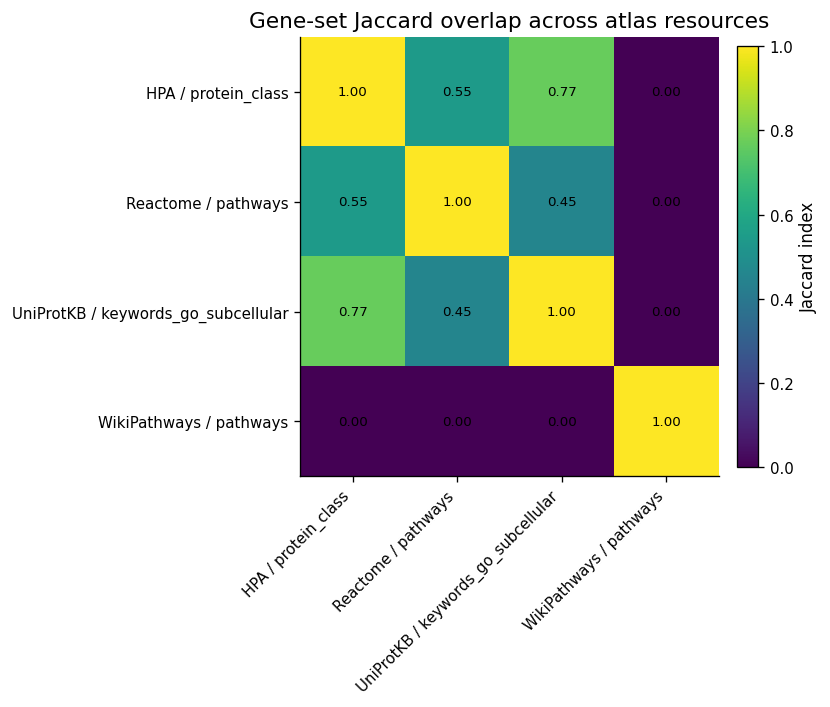

In [11]:
# 12. Cross-resource overlap on annotated genes

resource_gene_sets = {
    f"{src} / {coll}": set(sub["gene_symbol"].dropna())
    for (src, coll), sub in atlas_long.groupby(["source", "collection"])
}

labels = list(resource_gene_sets.keys())
rows = []
for a in labels:
    for b in labels:
        A = resource_gene_sets[a]
        B = resource_gene_sets[b]
        inter = len(A & B)
        union = len(A | B)
        rows.append({
            "resource_a": a,
            "resource_b": b,
            "genes_a": len(A),
            "genes_b": len(B),
            "intersection_genes": inter,
            "union_genes": union,
            "jaccard": inter / union if union else np.nan,
            "coverage_of_a_by_b": inter / len(A) if A else np.nan,
            "coverage_of_b_by_a": inter / len(B) if B else np.nan,
        })

overlap_df = pd.DataFrame(rows)
display(overlap_df.head(20))
overlap_df.to_csv(TABLES_DIR / "resource_gene_overlap.csv", index=False)

jaccard = overlap_df.pivot(index="resource_a", columns="resource_b", values="jaccard").reindex(index=labels, columns=labels)
fig, ax = plt.subplots(figsize=(max(7, 0.7 * len(labels)), max(6, 0.65 * len(labels))))
im = ax.imshow(jaccard.values, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
ax.set_title("Gene-set Jaccard overlap across atlas resources")
for i in range(len(labels)):
    for j in range(len(labels)):
        val = jaccard.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Jaccard index")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "resource_gene_jaccard_heatmap.png", bbox_inches="tight")
plt.show()


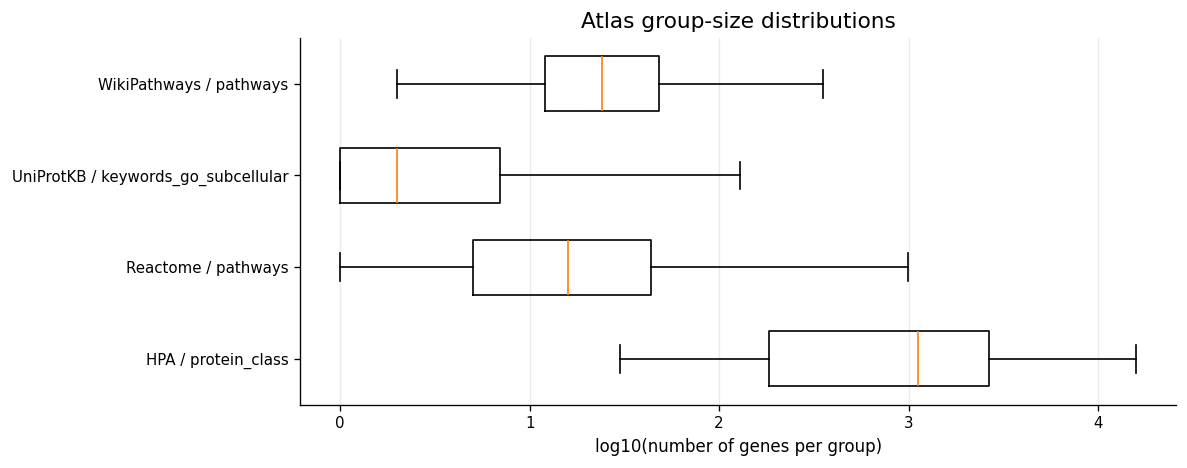

In [12]:
# 13. Group-size distributions

plot_data = group_sizes.copy()
plot_data = plot_data.loc[plot_data["group_size_genes"] > 0].copy()
plot_data["resource"] = plot_data["source"] + " / " + plot_data["collection"]
resources = plot_data["resource"].drop_duplicates().tolist()

fig, ax = plt.subplots(figsize=(10, max(4, 0.55 * len(resources))))
positions = np.arange(len(resources))
values = [np.log10(plot_data.loc[plot_data["resource"] == r, "group_size_genes"].values) for r in resources]
ax.boxplot(values, vert=False, positions=positions, widths=0.6, showfliers=False)
ax.set_yticks(positions)
ax.set_yticklabels(resources)
ax.set_xlabel("log10(number of genes per group)")
ax.set_title("Atlas group-size distributions")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "group_size_distribution_boxplots.png", bbox_inches="tight")
plt.show()


In [13]:
# 14. Evidence-code composition for GOA

if "GOA" in set(atlas_long["source"]):
    goa_evidence = (
        atlas_long.loc[(atlas_long["source"] == "GOA") & atlas_long["evidence"].notna()]
        .drop_duplicates(["gene_symbol", "group_name", "evidence"])
        .groupby("evidence", as_index=False)
        .agg(memberships=("group_name", "size"), genes=("gene_symbol", "nunique"), groups=("group_name", "nunique"))
        .sort_values("memberships", ascending=False)
    )
    display(goa_evidence)
    goa_evidence.to_csv(TABLES_DIR / "goa_evidence_code_composition.csv", index=False)

    top = goa_evidence.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(top))))
    ax.barh(top["evidence"], top["memberships"])
    ax.set_xlabel("GOA memberships")
    ax.set_title("Top GOA evidence codes by annotation count")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "goa_evidence_codes.png", bbox_inches="tight")
    plt.show()
else:
    print("GOA was not parsed, so no evidence-code summary is available.")


GOA was not parsed, so no evidence-code summary is available.


In [14]:
# 15. Search utilities for manual inspection


def search_atlas_groups(pattern, source=None, min_size=1, max_rows=50):
    # Search group names and return group-level summaries.
    rx = re.compile(pattern, flags=re.I)
    df = group_sizes.loc[group_sizes["group_name"].map(lambda x: bool(rx.search(str(x))))].copy()
    if source is not None:
        df = df.loc[df["source"].str.lower() == str(source).lower()]
    df = df.loc[df["group_size_genes"] >= min_size]
    df = df.sort_values(["source", "collection", "group_size_genes"], ascending=[True, True, False])
    return df.head(max_rows)


def inspect_gene(gene_symbol, max_rows=100):
    # Show atlas memberships for one gene symbol.
    gene = clean_gene_symbol(gene_symbol)
    df = atlas_long.loc[atlas_long["gene_symbol"] == gene].copy()
    cols = ["source", "collection", "group_name", "uniprot_id", "ensembl_id", "evidence"]
    return df[cols].drop_duplicates().sort_values(["source", "collection", "group_name"]).head(max_rows)


def inspect_group(group_pattern, max_genes=100):
    # Show genes belonging to matching atlas groups.
    rx = re.compile(group_pattern, flags=re.I)
    df = atlas_long.loc[atlas_long["group_name"].map(lambda x: bool(rx.search(str(x))))].copy()
    cols = ["source", "collection", "group_name", "gene_symbol", "uniprot_id", "evidence"]
    return df[cols].drop_duplicates().sort_values(["source", "collection", "group_name", "gene_symbol"]).head(max_genes)

# Example searches; modify the pattern terms as needed.
display(search_atlas_groups("membrane|translation|RNA", max_rows=30))
display(inspect_gene("TP53", max_rows=40))


,source,collection,group_id,group_name,group_size_genes
17,HPA,protein_class,HPA | protein_class | Predicted membrane proteins,Predicted membrane proteins,5571
20,HPA,protein_class,HPA | protein_class | RNA polymerase related p...,RNA polymerase related proteins,34
1880,Reactome,pathways,Reactome | pathways | Post-translational prote...,Post-translational protein modification,1475
1994,Reactome,pathways,Reactome | pathways | RNA Polymerase II Transc...,RNA Polymerase II Transcription,1321
1516,Reactome,pathways,Reactome | pathways | Metabolism of RNA,Metabolism of RNA,792
1511,Reactome,pathways,Reactome | pathways | Membrane Trafficking,Membrane Trafficking,634
2695,Reactome,pathways,Reactome | pathways | Translation,Translation,399
1900,Reactome,pathways,Reactome | pathways | Processing of Capped Int...,Processing of Capped Intron-Containing Pre-mRNA,296
2265,Reactome,pathways,Reactome | pathways | SLC-mediated transmembra...,SLC-mediated transmembrane transport,244
2861,Reactome,pathways,Reactome | pathways | rRNA processing,rRNA processing,244


,source,collection,group_name,uniprot_id,ensembl_id,evidence
25441,HPA,protein_class,Cancer-related genes,P04637,ENSG00000141510,NaN
25442,HPA,protein_class,Disease related genes,P04637,ENSG00000141510,NaN
25443,HPA,protein_class,Human disease related genes,P04637,ENSG00000141510,NaN
25444,HPA,protein_class,Plasma proteins,P04637,ENSG00000141510,NaN
25445,HPA,protein_class,Potential drug targets,P04637,ENSG00000141510,NaN
25446,HPA,protein_class,Predicted intracellular proteins,P04637,ENSG00000141510,NaN
25447,HPA,protein_class,Transcription factors,P04637,ENSG00000141510,NaN
25448,HPA,protein_class,Transporters,P04637,ENSG00000141510,NaN
2489021,Reactome,pathways,Activation of BH3-only proteins,NaN,NaN,NaN
2489427,Reactome,pathways,Activation of NOXA and translocation to mitoch...,NaN,NaN,NaN


## 16. Interpretation guide

This notebook separates **atlas composition** from **model performance**.

Recommended checks before enrichment analysis:

- **Coverage.** A resource with many annotated genes may dominate downstream results simply because it covers more of the tested universe.
- **Group-size distribution.** Very large groups are useful for broad biological summaries but can be less specific. Very small groups can produce unstable enrichment results.
- **Annotation burden.** Some genes have many annotations, especially in UniProtKB and GOA. This can create repeated membership across related biological terms.
- **Cross-resource overlap.** Similar gene coverage across resources does not mean identical biological grouping. Gene-set Jaccard overlap helps separate resource coverage from group semantics.
- **Evidence-code mix.** GOA contains both manual and computational annotations; evidence-code composition should be inspected before interpreting GO-driven enrichment.

A defensible report sentence after running this notebook should mention which resources were present locally, how many groups and genes were parsed from each, and whether GO term names were available through `go-basic.obo`.


In [15]:
# 17. Export compact report tables

report = {
    "created_at": _dt.datetime.now().isoformat(timespec="seconds"),
    "base_dir": str(BASE_DIR.resolve()),
    "download_dir": str(DOWNLOAD_DIR.resolve()),
    "output_dir": str(OUTPUT_DIR.resolve()),
    "resource_zip": str(RESOURCE_ZIP.resolve()),
    "normalized_atlas_rows": int(len(atlas_long)),
    "normalized_atlas_groups": int(atlas_long["group_id"].nunique()),
    "normalized_atlas_genes": int(atlas_long["gene_symbol"].nunique()),
    "sources": sorted(atlas_long["source"].dropna().unique().tolist()),
}

with open(TABLES_DIR / "atlas_inspection_report.json", "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print(f"\nTables exported to: {TABLES_DIR.resolve()}")
print(f"Plots exported to: {PLOTS_DIR.resolve()}")


{
  "created_at": "2026-06-11T11:27:36",
  "base_dir": "C:\\Users\\hp\\Desktop\\CPPR\\Cancer-Protein-RNA-research\\04.5 ccle comparison",
  "download_dir": "C:\\Users\\hp\\Desktop\\CPPR\\Cancer-Protein-RNA-research\\04.5 ccle comparison\\pan_atlas_downloads",
  "output_dir": "C:\\Users\\hp\\Desktop\\CPPR\\Cancer-Protein-RNA-research\\04.5 ccle comparison\\pan_atlas_resource_inspection_outputs",
  "resource_zip": "C:\\Users\\hp\\Desktop\\CPPR\\Cancer-Protein-RNA-research\\04.5 ccle comparison\\pan_atlas_resources.zip",
  "normalized_atlas_rows": 2668045,
  "normalized_atlas_groups": 30729,
  "normalized_atlas_genes": 34807,
  "sources": [
    "HPA",
    "Reactome",
    "UniProtKB",
    "WikiPathways"
  ]
}

Tables exported to: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\tables
Plots exported to: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\plots


## 18. References

- Human Protein Atlas downloadable data: <https://www.proteinatlas.org/about/download>
- Uhlen M. et al. Tissue-based map of the human proteome. *Science* 2015.
- UniProt Consortium. UniProt: the Universal Protein Knowledgebase in 2025. *Nucleic Acids Research* 2025.
- Gene Ontology Consortium. The Gene Ontology knowledgebase in 2026. *Nucleic Acids Research* 2026.
- Gene Ontology annotation downloads: <https://current.geneontology.org/products/pages/downloads.html>
- Reactome Pathway Knowledgebase 2024. *Nucleic Acids Research* 2024.
- WikiPathways 2024: next generation pathway database. *Nucleic Acids Research* 2024.


## 19. Atlas-group capture by threshold set

This final section asks a different question from enrichment plots: **for each atlas group, what percentage of its member genes falls inside each model-performance threshold set?**

The denominator is the atlas group size inside the tested performance universe when a tested-universe table is available. Otherwise, the denominator falls back to the full parsed atlas group size. This makes the main quantity group-centered:

```text
percentage captured = 100 x captured group genes / atlas group genes in scope
```

The plots are designed for paper-style reporting and emphasize group capture rather than threshold-set composition.

In [16]:
# 19.1. Threshold-set loading helpers for atlas-group capture

CAPTURE_OUTPUT_DIR = OUTPUT_DIR / "atlas_group_capture"
CAPTURE_TABLES_DIR = CAPTURE_OUTPUT_DIR / "tables"
CAPTURE_PLOTS_DIR = CAPTURE_OUTPUT_DIR / "plots"
for d in [CAPTURE_OUTPUT_DIR, CAPTURE_TABLES_DIR, CAPTURE_PLOTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Minimum number of atlas-group genes in the selected denominator scope.
CAPTURE_MIN_GROUP_SIZE = 10

# Threshold definitions used when threshold membership must be reconstructed from a performance table.
CAPTURE_THRESHOLD_DEFINITIONS = [
    {"condition": "Pearson >= 0.50", "metric": "pearson", "operator": ">=", "value": 0.50},
    {"condition": "Pearson >= 0.70", "metric": "pearson", "operator": ">=", "value": 0.70},
    {"condition": "Cosine >= 0.50", "metric": "cosine", "operator": ">=", "value": 0.50},
    {"condition": "Cosine >= 0.70", "metric": "cosine", "operator": ">=", "value": 0.70},
    {"condition": "MSE <= 0.25", "metric": "mse", "operator": "<=", "value": 0.25},
]
CAPTURE_CONDITION_ORDER = [d["condition"] for d in CAPTURE_THRESHOLD_DEFINITIONS]

# Optional manual paths. Leave empty when standard pan-atlas output paths are available.
CAPTURE_THRESHOLD_MEMBERSHIP_PATHS = []
CAPTURE_BEST_METRICS_PATHS = []
CAPTURE_PERFORMANCE_TABLE_PATHS = []


def capture_slug(x):
    return re.sub(r"[^a-zA-Z0-9]+", "_", str(x).strip().lower()).strip("_")


def capture_savefig(fig, stem):
    png_path = CAPTURE_PLOTS_DIR / f"{stem}.png"
    svg_path = CAPTURE_PLOTS_DIR / f"{stem}.svg"
    fig.savefig(png_path, bbox_inches="tight", facecolor="white")
    fig.savefig(svg_path, bbox_inches="tight", facecolor="white")
    print(f"Saved: {png_path}")
    print(f"Saved: {svg_path}")


def capture_read_table(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    if path.suffix.lower() in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\t")
    return pd.read_csv(path)


def capture_clean_gene(x):
    try:
        return clean_gene_symbol(x)
    except Exception:
        if pd.isna(x):
            return pd.NA
        x = str(x).strip()
        if not x:
            return pd.NA
        return re.sub(r"\.\d+$", "", x.split(";")[0].split(",")[0].split("|")[0].strip()).upper()


def capture_norm_col(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())


def capture_choose_col(columns, aliases, required=False):
    columns = list(columns)
    direct = {str(c).lower(): c for c in columns}
    normalized = {capture_norm_col(c): c for c in columns}
    for alias in aliases:
        if str(alias).lower() in direct:
            return direct[str(alias).lower()]
    for alias in aliases:
        key = capture_norm_col(alias)
        if key in normalized:
            return normalized[key]
    for alias in aliases:
        key = capture_norm_col(alias)
        for col in columns:
            if key and key in capture_norm_col(col):
                return col
    if required:
        raise ValueError(f"Required column not found. Available columns: {columns[:80]}")
    return None


def capture_standardize_best_metrics(df):
    out = df.copy()
    protein_col = capture_choose_col(out.columns, ["protein_key", "protein", "protein_raw", "target", "gene", "gene_symbol"], required=True)
    gene_col = capture_choose_col(out.columns, ["gene_symbol", "gene", "protein_key", "protein", "target"], required=False)
    pearson_col = capture_choose_col(out.columns, ["pearson", "test_pearson", "pearson_corr", "correlation", "corr", "r"], required=False)
    cosine_col = capture_choose_col(out.columns, ["cosine", "cosine_similarity", "test_cosine", "cos_sim"], required=False)
    mse_col = capture_choose_col(out.columns, ["mse", "test_mse", "mean_squared_error"], required=False)

    std = pd.DataFrame({
        "protein_key": out[protein_col].astype("string").str.strip(),
        "gene_symbol": out[gene_col].map(capture_clean_gene) if gene_col else out[protein_col].map(capture_clean_gene),
    })
    std["pearson"] = pd.to_numeric(out[pearson_col], errors="coerce") if pearson_col else np.nan
    std["cosine"] = pd.to_numeric(out[cosine_col], errors="coerce") if cosine_col else np.nan
    std["mse"] = pd.to_numeric(out[mse_col], errors="coerce") if mse_col else np.nan
    std = std.dropna(subset=["protein_key", "gene_symbol"]).drop_duplicates()
    return std


def capture_standardize_performance_table(df):
    raw = df.copy()
    protein_col = capture_choose_col(raw.columns, ["protein_key", "protein_raw", "protein", "target", "gene", "gene_symbol", "symbol"], required=True)
    method_col = capture_choose_col(raw.columns, ["method", "model", "family", "model_family", "source", "approach"], required=False)
    pearson_col = capture_choose_col(raw.columns, ["pearson", "test_pearson", "pearson_corr", "correlation", "corr", "r"], required=False)
    cosine_col = capture_choose_col(raw.columns, ["cosine", "cosine_similarity", "test_cosine", "cos_sim"], required=False)
    mse_col = capture_choose_col(raw.columns, ["mse", "test_mse", "mean_squared_error"], required=False)

    std = pd.DataFrame({
        "protein_key": raw[protein_col].astype("string").str.strip(),
        "gene_symbol": raw[protein_col].map(capture_clean_gene),
        "method": raw[method_col].astype("string") if method_col else "unknown",
    })
    std["pearson"] = pd.to_numeric(raw[pearson_col], errors="coerce") if pearson_col else np.nan
    std["cosine"] = pd.to_numeric(raw[cosine_col], errors="coerce") if cosine_col else np.nan
    std["mse"] = pd.to_numeric(raw[mse_col], errors="coerce") if mse_col else np.nan
    std = std.dropna(subset=["protein_key", "gene_symbol"]).drop_duplicates()

    best = (
        std.groupby(["protein_key", "gene_symbol"], dropna=False)
        .agg(pearson=("pearson", "max"), cosine=("cosine", "max"), mse=("mse", "min"))
        .reset_index()
    )
    return best


def capture_build_threshold_membership(best):
    rows = []
    best = capture_standardize_best_metrics(best)
    for spec in CAPTURE_THRESHOLD_DEFINITIONS:
        metric = spec["metric"]
        if metric not in best.columns:
            continue
        if spec["operator"] == ">=":
            mask = best[metric] >= spec["value"]
        elif spec["operator"] == "<=":
            mask = best[metric] <= spec["value"]
        else:
            raise ValueError(spec["operator"])
        temp = best.loc[mask.fillna(False), ["protein_key", "gene_symbol", "pearson", "cosine", "mse"]].copy()
        temp["condition"] = spec["condition"]
        rows.append(temp)
    if not rows:
        return pd.DataFrame(columns=["condition", "protein_key", "gene_symbol", "pearson", "cosine", "mse"])
    return pd.concat(rows, ignore_index=True).drop_duplicates()


def capture_standardize_threshold_membership(df):
    raw = df.copy()
    cond_col = capture_choose_col(raw.columns, ["condition", "threshold", "threshold_set", "set_name"], required=True)
    protein_col = capture_choose_col(raw.columns, ["protein_key", "protein", "protein_raw", "target", "gene", "gene_symbol"], required=True)
    gene_col = capture_choose_col(raw.columns, ["gene_symbol", "gene", "protein_key", "protein", "target"], required=False)
    out = pd.DataFrame({
        "condition": raw[cond_col].astype("string"),
        "protein_key": raw[protein_col].astype("string").str.strip(),
        "gene_symbol": raw[gene_col].map(capture_clean_gene) if gene_col else raw[protein_col].map(capture_clean_gene),
    })
    for metric in ["pearson", "cosine", "mse"]:
        col = capture_choose_col(raw.columns, [metric, f"test_{metric}"], required=False)
        out[metric] = pd.to_numeric(raw[col], errors="coerce") if col else np.nan
    return out.dropna(subset=["condition", "protein_key", "gene_symbol"]).drop_duplicates()


def capture_candidate_paths():
    table_roots = [
        TABLES_DIR,
        OUTPUT_DIR / "tables",
        BASE_DIR / "pan_atlas_outputs" / "tables",
        BASE_DIR / "pan_atlas_clean_outputs" / "tables",
        BASE_DIR / "atlas_outputs",
        BASE_DIR / "comparison_outputs",
        BASE_DIR / "output",
    ]
    membership_names = [
        "threshold_set_membership_long.csv",
        "threshold_membership_individual_sets.csv",
        "threshold_membership.csv",
    ]
    best_names = [
        "best_metrics_per_protein.csv",
        "best_model_per_protein_all_metrics.csv",
        "atlas_performance_standardized.csv",
        "all_model_results_summary.csv",
    ]
    membership_paths = [Path(p) for p in CAPTURE_THRESHOLD_MEMBERSHIP_PATHS]
    best_paths = [Path(p) for p in CAPTURE_BEST_METRICS_PATHS]
    perf_paths = [Path(p) for p in CAPTURE_PERFORMANCE_TABLE_PATHS]
    for root in table_roots:
        for name in membership_names:
            membership_paths.append(Path(root) / name)
        for name in best_names:
            best_paths.append(Path(root) / name)
    for name in best_names:
        perf_paths.append(BASE_DIR / name)
    return membership_paths, best_paths, perf_paths


def capture_load_threshold_inputs():
    membership_paths, best_paths, perf_paths = capture_candidate_paths()

    best_for_capture = None
    if "best_metrics" in globals() and isinstance(best_metrics, pd.DataFrame) and not best_metrics.empty:
        best_for_capture = capture_standardize_best_metrics(best_metrics)
        print("Using in-memory best_metrics for the tested universe.")
    else:
        for path in best_paths:
            if Path(path).exists():
                try:
                    best_for_capture = capture_standardize_best_metrics(capture_read_table(path))
                    print(f"Loaded tested-universe metrics from: {path}")
                    break
                except Exception as e:
                    print(f"Skipped best-metrics candidate {path}: {e}")

    threshold_for_capture = None
    if "threshold_membership" in globals() and isinstance(threshold_membership, pd.DataFrame) and not threshold_membership.empty:
        threshold_for_capture = capture_standardize_threshold_membership(threshold_membership)
        print("Using in-memory threshold_membership.")
    else:
        for path in membership_paths:
            if Path(path).exists():
                try:
                    threshold_for_capture = capture_standardize_threshold_membership(capture_read_table(path))
                    print(f"Loaded threshold membership from: {path}")
                    break
                except Exception as e:
                    print(f"Skipped threshold candidate {path}: {e}")

    if threshold_for_capture is None and best_for_capture is not None:
        threshold_for_capture = capture_build_threshold_membership(best_for_capture)
        print("Reconstructed threshold membership from best-per-protein metrics.")

    if threshold_for_capture is None:
        for path in perf_paths:
            if Path(path).exists():
                try:
                    best_for_capture = capture_standardize_performance_table(capture_read_table(path))
                    threshold_for_capture = capture_build_threshold_membership(best_for_capture)
                    print(f"Reconstructed threshold membership from performance table: {path}")
                    break
                except Exception as e:
                    print(f"Skipped performance candidate {path}: {e}")

    if threshold_for_capture is None or threshold_for_capture.empty:
        raise FileNotFoundError(
            "No threshold membership could be found or reconstructed. "
            "Set CAPTURE_THRESHOLD_MEMBERSHIP_PATHS, CAPTURE_BEST_METRICS_PATHS, or CAPTURE_PERFORMANCE_TABLE_PATHS."
        )

    threshold_for_capture["condition"] = pd.Categorical(
        threshold_for_capture["condition"].astype(str),
        categories=CAPTURE_CONDITION_ORDER,
        ordered=True,
    )
    threshold_for_capture = threshold_for_capture.loc[threshold_for_capture["condition"].notna()].copy()

    if best_for_capture is not None and not best_for_capture.empty:
        best_for_capture["gene_symbol"] = best_for_capture["gene_symbol"].map(capture_clean_gene)
        best_for_capture = best_for_capture.dropna(subset=["gene_symbol"]).drop_duplicates()

    return threshold_for_capture, best_for_capture


try:
    threshold_membership_capture, best_metrics_capture = capture_load_threshold_inputs()
    threshold_capture_ready = True
    print(f"Threshold rows: {len(threshold_membership_capture):,}")
    print(f"Threshold genes: {threshold_membership_capture['gene_symbol'].nunique():,}")
    if best_metrics_capture is not None:
        print(f"Tested-universe genes: {best_metrics_capture['gene_symbol'].nunique():,}")
except Exception as e:
    threshold_membership_capture = pd.DataFrame()
    best_metrics_capture = None
    threshold_capture_ready = False
    print(f"Atlas-group capture section skipped for now: {e}")


Loaded tested-universe metrics from: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\best_metrics_per_protein.csv
Loaded threshold membership from: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\threshold_set_membership_long.csv
Threshold rows: 12,735
Threshold genes: 4,684
Tested-universe genes: 5,113


In [17]:
# 19.2. Compute atlas-group capture percentages

if not threshold_capture_ready:
    group_capture = pd.DataFrame()
    group_capture_summary = pd.DataFrame()
    print("No threshold data available, so atlas-group capture percentages were not computed.")
else:
    if "atlas_long" not in globals() or atlas_long.empty:
        raise RuntimeError("atlas_long is required. Run the atlas parsing cells before this section.")

    threshold_membership_capture = threshold_membership_capture.copy()
    threshold_membership_capture["gene_symbol"] = threshold_membership_capture["gene_symbol"].map(capture_clean_gene)
    threshold_membership_capture = threshold_membership_capture.dropna(subset=["gene_symbol"]).drop_duplicates()

    if best_metrics_capture is not None and not best_metrics_capture.empty:
        denominator_scope = "tested performance universe"
        universe_genes_capture = set(best_metrics_capture["gene_symbol"].dropna())
    else:
        denominator_scope = "full parsed atlas genes"
        universe_genes_capture = set(atlas_long["gene_symbol"].dropna().map(capture_clean_gene))

    atlas_group_gene = (
        atlas_long
        .dropna(subset=["gene_symbol", "group_id", "group_name"])
        .assign(gene_symbol=lambda d: d["gene_symbol"].map(capture_clean_gene))
        .dropna(subset=["gene_symbol"])
        .drop_duplicates(["source", "collection", "group_id", "group_name", "gene_symbol"])
    )
    atlas_group_gene = atlas_group_gene.loc[atlas_group_gene["gene_symbol"].isin(universe_genes_capture)].copy()

    group_denominators = (
        atlas_group_gene
        .groupby(["source", "collection", "group_id", "group_name"], as_index=False)
        .agg(group_size_in_scope=("gene_symbol", "nunique"))
    )
    group_denominators = group_denominators.loc[group_denominators["group_size_in_scope"] >= CAPTURE_MIN_GROUP_SIZE].copy()
    valid_capture_groups = set(group_denominators["group_id"])
    atlas_group_gene = atlas_group_gene.loc[atlas_group_gene["group_id"].isin(valid_capture_groups)].copy()

    threshold_gene_sets = {
        str(cond): set(sub["gene_symbol"].dropna())
        for cond, sub in threshold_membership_capture.groupby("condition", observed=False)
        if str(cond) != "nan"
    }

    rows = []
    for condition in CAPTURE_CONDITION_ORDER:
        condition_genes = threshold_gene_sets.get(condition, set())
        if not condition_genes:
            continue
        tmp = atlas_group_gene.copy()
        tmp["is_captured"] = tmp["gene_symbol"].isin(condition_genes)
        captured = (
            tmp.groupby(["source", "collection", "group_id", "group_name"], as_index=False)
            .agg(captured_genes=("is_captured", "sum"))
        )
        captured["condition"] = condition
        captured["threshold_set_size_genes"] = len(condition_genes)
        rows.append(captured)

    group_capture = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if not group_capture.empty:
        group_capture = group_capture.merge(
            group_denominators,
            on=["source", "collection", "group_id", "group_name"],
            how="left",
        )
        group_capture["pct_group_captured"] = 100 * group_capture["captured_genes"] / group_capture["group_size_in_scope"]
        group_capture["pct_threshold_set_in_group"] = 100 * group_capture["captured_genes"] / group_capture["threshold_set_size_genes"]
        group_capture["denominator_scope"] = denominator_scope
        group_capture["condition"] = pd.Categorical(group_capture["condition"], categories=CAPTURE_CONDITION_ORDER, ordered=True)
        group_capture = group_capture.sort_values(
            ["condition", "pct_group_captured", "captured_genes", "group_size_in_scope"],
            ascending=[True, False, False, False],
        ).reset_index(drop=True)

        group_capture["rank_within_condition_by_group_pct"] = (
            group_capture.groupby("condition", observed=False)["pct_group_captured"]
            .rank(method="first", ascending=False)
        )

        summary_rows = []
        for condition, sub in group_capture.groupby("condition", observed=False):
            if sub.empty:
                continue
            summary_rows.append({
                "condition": str(condition),
                "groups_evaluated": int(sub["group_id"].nunique()),
                "median_pct_group_captured": float(sub["pct_group_captured"].median()),
                "max_pct_group_captured": float(sub["pct_group_captured"].max()),
                "groups_at_least_25pct_captured": int((sub["pct_group_captured"] >= 25).sum()),
                "groups_at_least_50pct_captured": int((sub["pct_group_captured"] >= 50).sum()),
                "groups_at_least_75pct_captured": int((sub["pct_group_captured"] >= 75).sum()),
            })
        group_capture_summary = pd.DataFrame(summary_rows)

        group_capture.to_csv(CAPTURE_TABLES_DIR / "atlas_group_capture_by_threshold.csv", index=False)
        group_capture_summary.to_csv(CAPTURE_TABLES_DIR / "atlas_group_capture_summary.csv", index=False)

        print(f"Denominator scope: {denominator_scope}")
        print(f"Groups evaluated: {group_denominators['group_id'].nunique():,}")
        print(f"Minimum group size in scope: {CAPTURE_MIN_GROUP_SIZE}")
        display(group_capture_summary)

        top_preview = (
            group_capture
            .loc[group_capture["rank_within_condition_by_group_pct"] <= 8,
                 ["condition", "source", "collection", "group_name", "group_size_in_scope", "captured_genes", "pct_group_captured"]]
            .copy()
        )
        display(top_preview)
    else:
        group_capture_summary = pd.DataFrame()
        print("No capture rows were produced.")


Denominator scope: tested performance universe
Groups evaluated: 3,120
Minimum group size in scope: 10


,condition,groups_evaluated,median_pct_group_captured,max_pct_group_captured,groups_at_least_25pct_captured,groups_at_least_50pct_captured,groups_at_least_75pct_captured
0,Pearson >= 0.50,3120,72.727273,100.0,2963,2569,1460
1,Pearson >= 0.70,3120,25.000000,100.0,1587,540,75
2,Cosine >= 0.50,3120,73.956522,100.0,2985,2665,1530
3,Cosine >= 0.70,3120,25.000000,100.0,1599,561,76
4,MSE <= 0.25,3120,50.000000,100.0,2728,1690,645


,condition,source,collection,group_name,group_size_in_scope,captured_genes,pct_group_captured
0,Pearson >= 0.50,UniProtKB,keywords_go_subcellular,sarcolemma,37,37,100.000000
1,Pearson >= 0.50,UniProtKB,keywords_go_subcellular,LIM domain,32,32,100.000000
2,Pearson >= 0.50,UniProtKB,keywords_go_subcellular,Steroid metabolism,31,31,100.000000
3,Pearson >= 0.50,Reactome,pathways,Collagen formation,28,28,100.000000
4,Pearson >= 0.50,Reactome,pathways,Glycosaminoglycan metabolism,28,28,100.000000
5,Pearson >= 0.50,UniProtKB,keywords_go_subcellular,Sterol metabolism,28,28,100.000000
6,Pearson >= 0.50,UniProtKB,keywords_go_subcellular,Cholesterol metabolism,27,27,100.000000
7,Pearson >= 0.50,Reactome,pathways,Integrin cell surface interactions,26,26,100.000000
3120,Pearson >= 0.70,Reactome,pathways,Collagen degradation,15,15,100.000000
3121,Pearson >= 0.70,Reactome,pathways,Collagen biosynthesis and modifying enzymes,19,18,94.736842


Atlas-group capture summary
Minimum atlas group size in scope: 10
Counts below show how many atlas groups have at least the given percentage
of their gene-symbol protein entries captured by each threshold set.
------------------------------------------------------------------------------

Pearson >= 0.50
  Atlas groups evaluated: 3,120
  >=  90% captured:   553 groups ( 17.7%)
  >=  95% captured:   220 groups (  7.1%)
  >= 100% captured:   155 groups (  5.0%)
  Largest 100%-captured groups:
    - UniProtKB | sarcolemma: 37/37
    - UniProtKB | LIM domain: 32/32
    - UniProtKB | Steroid metabolism: 31/31
    - Reactome | Collagen formation: 28/28
    - Reactome | Glycosaminoglycan metabolism: 28/28

Pearson >= 0.70
  Atlas groups evaluated: 3,120
  >=  90% captured:    12 groups (  0.4%)
  >=  95% captured:     1 groups (  0.0%)
  >= 100% captured:     1 groups (  0.0%)
  Largest 100%-captured groups:
    - Reactome | Collagen degradation: 15/15

Cosine >= 0.50
  Atlas groups evaluated

C:\Users\hp\AppData\Local\Temp\ipykernel_9096\3383010484.py:49: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  plot_df.pivot_table(


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_capture_heatmap_horizontal_segmented.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_capture_heatmap_horizontal_segmented.svg


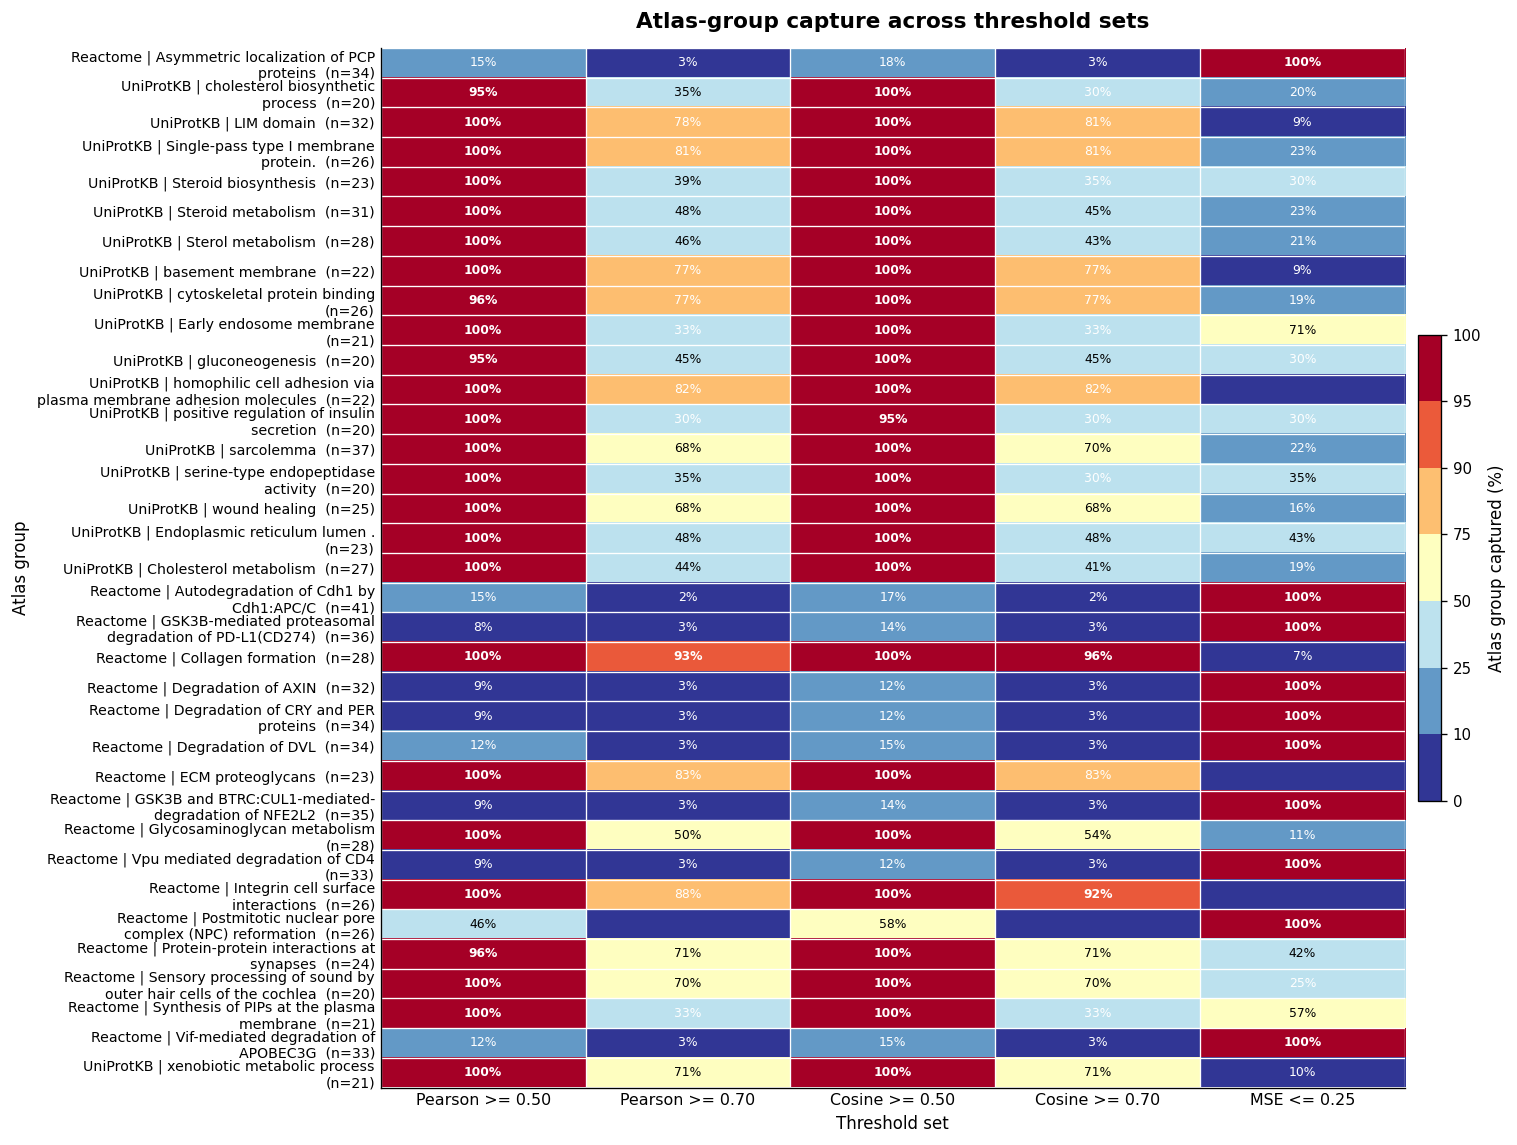

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_capture_survival_curves.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_capture_survival_curves.svg


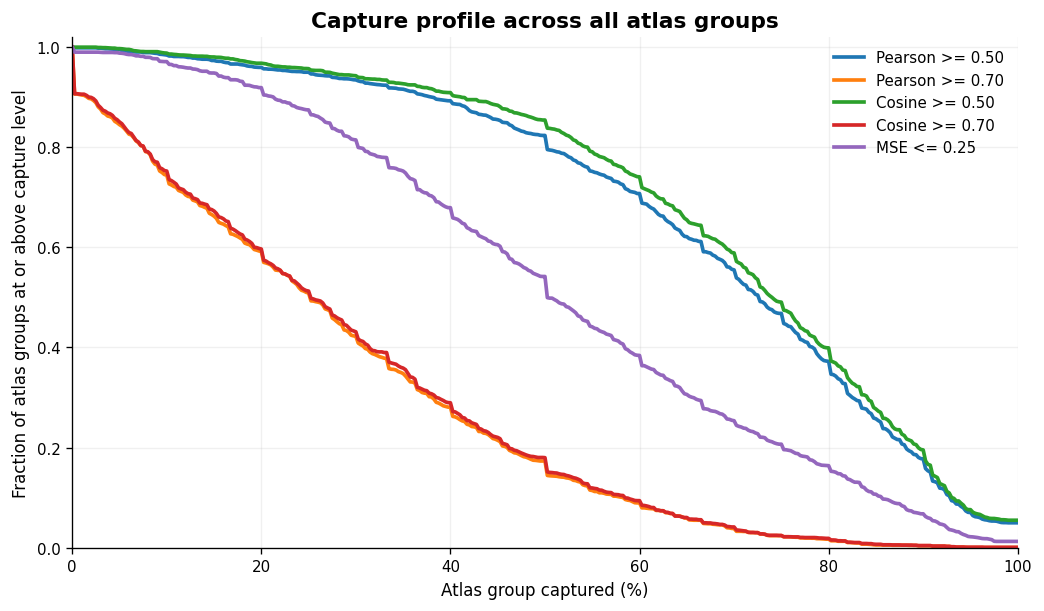

C:\Users\hp\AppData\Local\Temp\ipykernel_9096\3383010484.py:185: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  strong.pivot_table(


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_strong_capture_source_heatmap_50pct.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_strong_capture_source_heatmap_50pct.svg


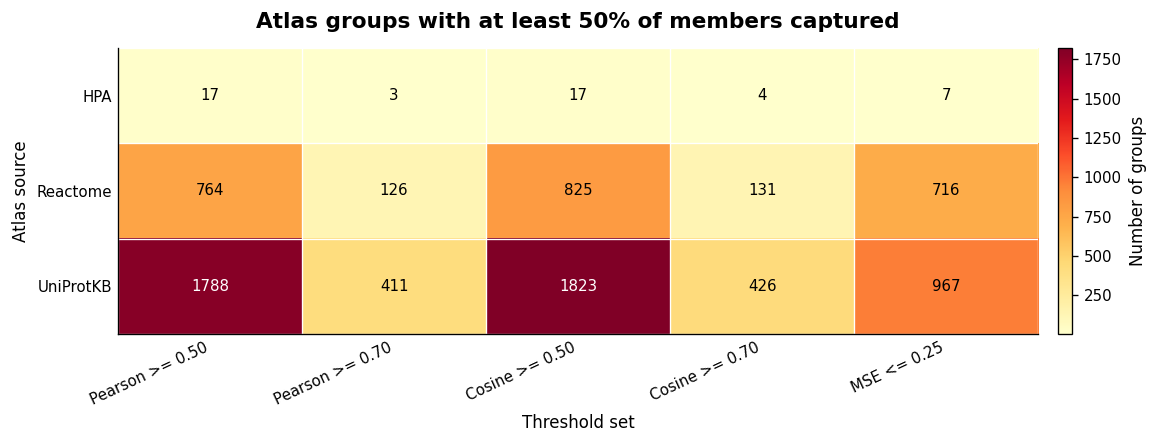

C:\Users\hp\AppData\Local\Temp\ipykernel_9096\3383010484.py:185: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  strong.pivot_table(


Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_strong_capture_source_heatmap_75pct.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_strong_capture_source_heatmap_75pct.svg


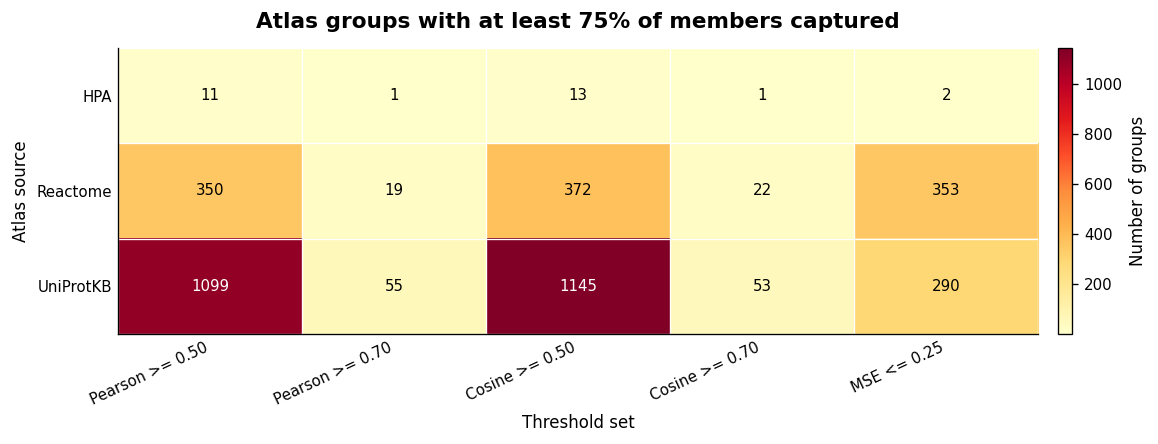

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_pearson_0_50.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_pearson_0_50.svg


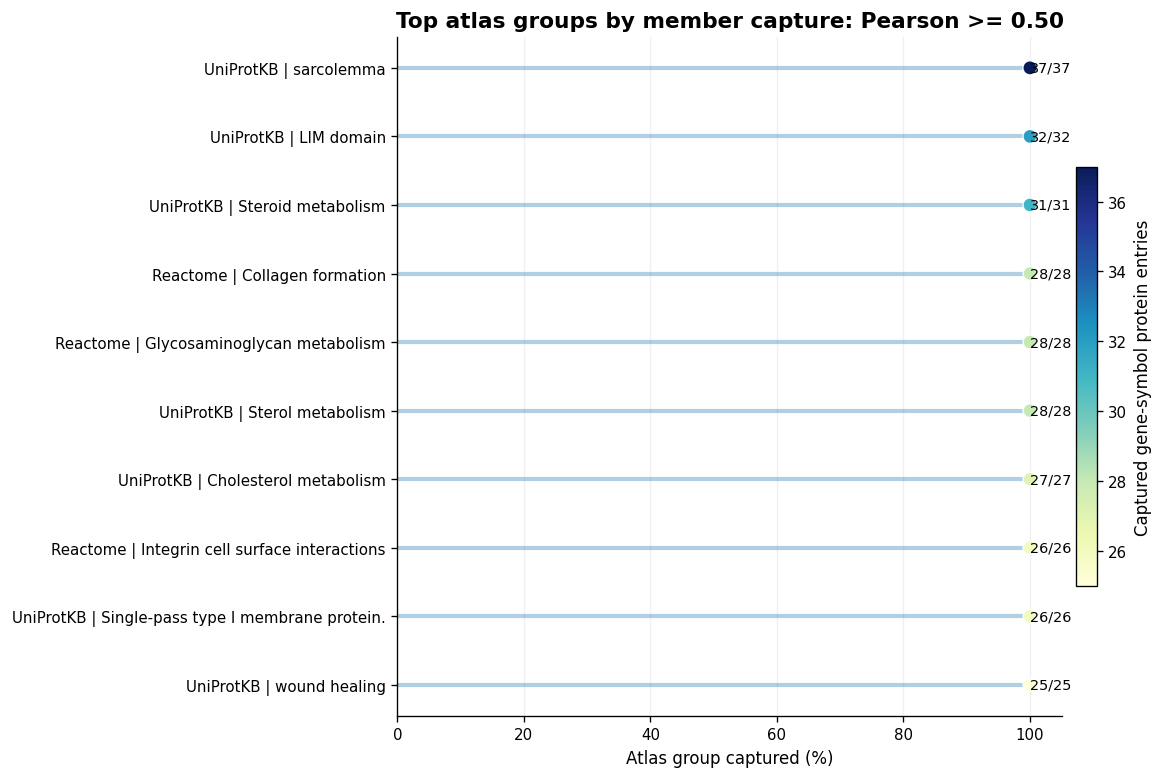

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_pearson_0_70.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_pearson_0_70.svg


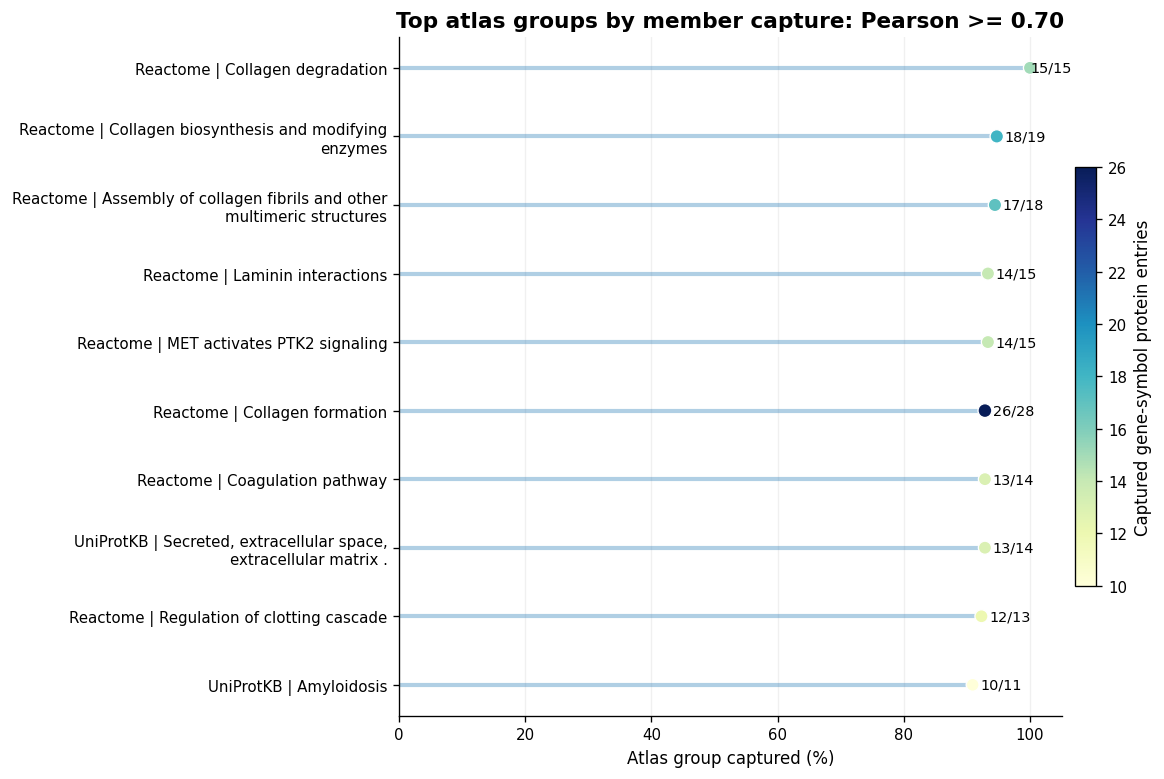

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_cosine_0_50.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_cosine_0_50.svg


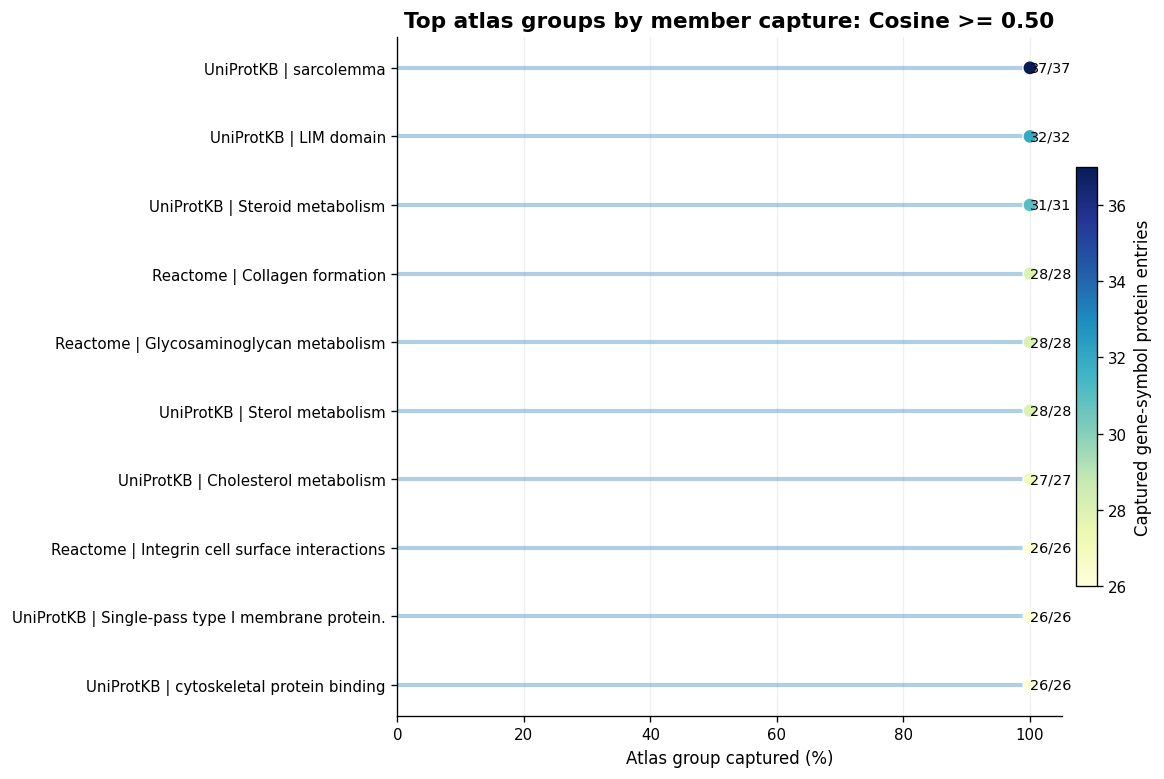

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_cosine_0_70.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_cosine_0_70.svg


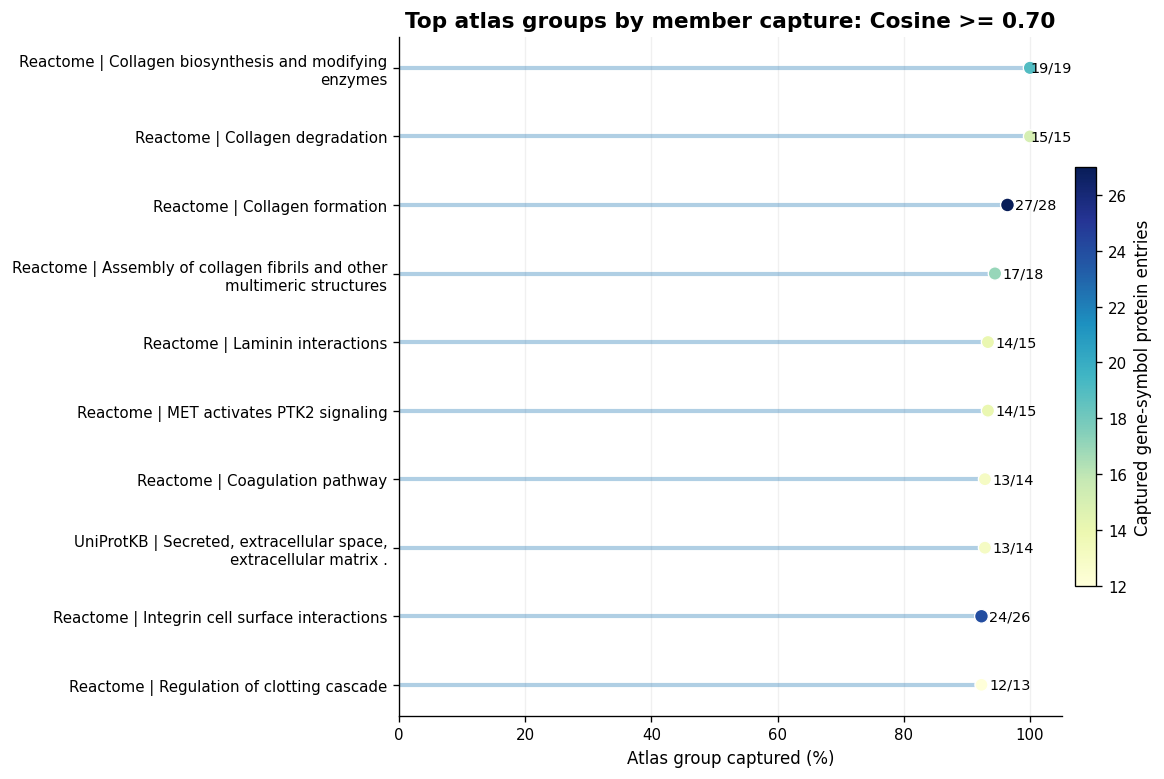

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_mse_0_25.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\top_atlas_group_capture_mse_0_25.svg


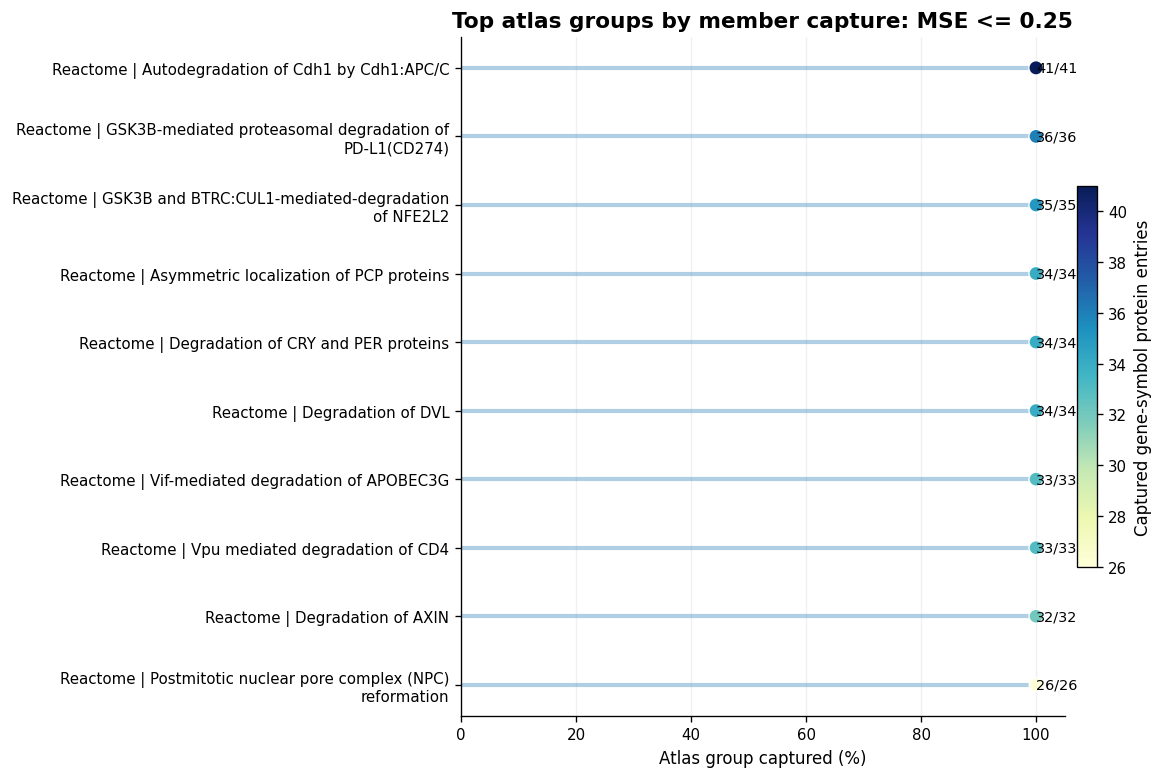

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_size_vs_best_capture.png
Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resource_inspection_outputs\atlas_group_capture\plots\atlas_group_size_vs_best_capture.svg


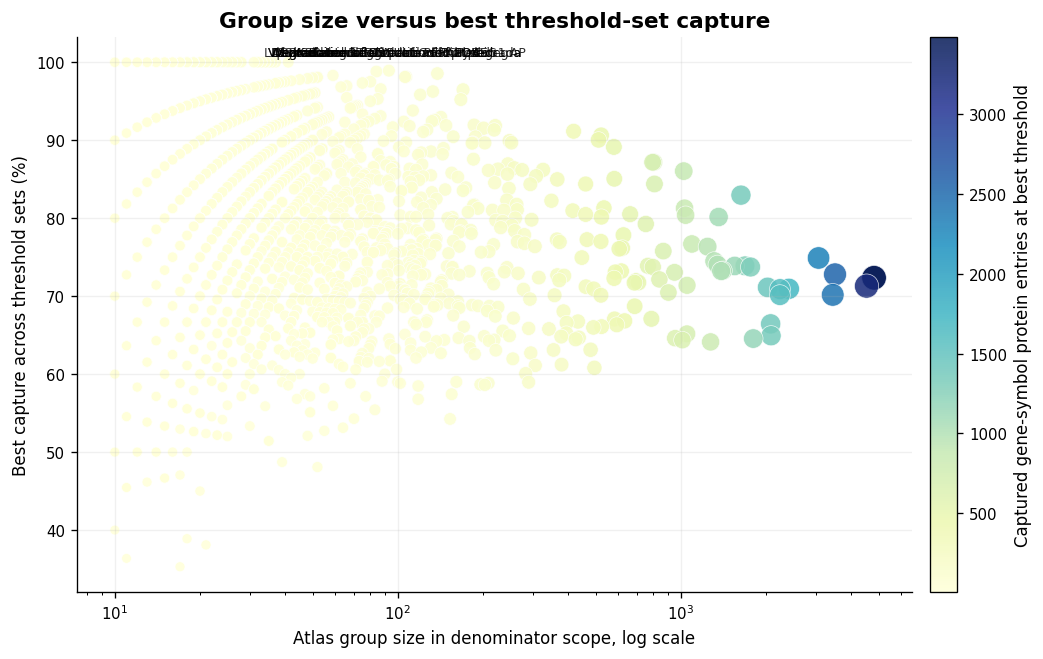

In [25]:
# 19.3. atlas-group capture plots

import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm


def capture_wrap_label(x, width=54):
    return "\n".join(textwrap.wrap(str(x), width=width, break_long_words=False))


def capture_checked_table(min_group_size=CAPTURE_MIN_GROUP_SIZE):
    if "group_capture" not in globals() or group_capture.empty:
        print("No group_capture table available.")
        return pd.DataFrame()

    df = group_capture.loc[group_capture["group_size_in_scope"] >= min_group_size].copy()
    df = df.loc[df["condition"].astype(str).isin(CAPTURE_CONDITION_ORDER)].copy()
    return df


def plot_group_capture_heatmap(max_groups=22, min_group_size=CAPTURE_MIN_GROUP_SIZE):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    ranked_groups = (
        df.groupby(["source", "collection", "group_id", "group_name"], as_index=False)
        .agg(
            max_pct_captured=("pct_group_captured", "max"),
            max_captured_genes=("captured_genes", "max"),
            group_size_in_scope=("group_size_in_scope", "max"),
        )
        .sort_values(
            ["max_pct_captured", "max_captured_genes", "group_size_in_scope"],
            ascending=[False, False, False],
        )
    )

    if max_groups is not None:
        ranked_groups = ranked_groups.head(max_groups)

    keep = set(ranked_groups["group_id"])
    plot_df = df.loc[df["group_id"].isin(keep)].copy()

    pivot = (
        plot_df.pivot_table(
            index=["source", "collection", "group_id", "group_name", "group_size_in_scope"],
            columns="condition",
            values="pct_group_captured",
            aggfunc="max",
        )
        .reindex(columns=CAPTURE_CONDITION_ORDER)
        .fillna(0)
    )

    order = pivot.max(axis=1).sort_values(ascending=False).index
    pivot = pivot.loc[order]

    labels = [
        capture_wrap_label(f"{idx[0]} | {idx[3]}  (n={int(idx[4])})", width=42)
        for idx in pivot.index
    ]

    fig_w = 15.5
    fig_h = max(5.2, 0.27 * len(pivot) + 1.8)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    # Segmented color scale for clearer PPT display.
    # Low capture = blue; high capture = yellow/red.
    cmap = plt.get_cmap("RdYlBu_r")
    bounds = [0, 10, 25, 50, 75, 90, 95, 100]
    norm = BoundaryNorm(bounds, cmap.N)

    im = ax.imshow(
        pivot.values,
        aspect="auto",
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )

    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=0, ha="center", fontsize=9.5)

    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels, fontsize=8.5)

    ax.set_title("Atlas-group capture across threshold sets", fontweight="bold", pad=12)
    ax.set_xlabel("Threshold set")
    ax.set_ylabel("Atlas group")

    # Thin white grid between cells.
    ax.set_xticks(np.arange(-0.5, len(pivot.columns), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(pivot.index), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.iloc[i, j]
            if val >= 1:
                txt_color = "white" if val < 35 or val >= 75 else "black"
                ax.text(
                    j,
                    i,
                    f"{val:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=7.4,
                    color=txt_color,
                    fontweight="bold" if val >= 90 else "normal",
                )

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.022,
        pad=0.012,
        ticks=bounds,
        boundaries=bounds,
    )
    cbar.set_label("Atlas group captured (%)")
    cbar.ax.set_yticklabels([str(x) for x in bounds])

    ax.tick_params(axis="both", length=0)

    # Wider, more horizontal layout for PowerPoint.
    fig.subplots_adjust(left=0.36, right=0.93, top=0.90, bottom=0.13)

    capture_savefig(fig, "atlas_group_capture_heatmap_horizontal_segmented")
    plt.show()


def plot_capture_survival_curves(min_group_size=CAPTURE_MIN_GROUP_SIZE):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    fig, ax = plt.subplots(figsize=(8.8, 5.2))

    for condition in CAPTURE_CONDITION_ORDER:
        vals = (
            df.loc[df["condition"].astype(str) == condition, "pct_group_captured"]
            .dropna()
            .sort_values()
            .values
        )

        if len(vals) == 0:
            continue

        x = np.linspace(0, 100, 401)
        y = np.array([(vals >= v).mean() for v in x])
        ax.plot(x, y, linewidth=2.2, label=condition)

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Atlas group captured (%)")
    ax.set_ylabel("Fraction of atlas groups at or above capture level")
    ax.set_title("Capture profile across all atlas groups", fontweight="bold")
    ax.grid(axis="both", alpha=0.18)
    ax.legend(frameon=False, ncol=1)

    fig.tight_layout()
    capture_savefig(fig, "atlas_group_capture_survival_curves")
    plt.show()


def plot_strong_capture_source_heatmap(capture_cutoff=50, min_group_size=CAPTURE_MIN_GROUP_SIZE):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    strong = df.loc[df["pct_group_captured"] >= capture_cutoff].copy()

    if strong.empty:
        print(f"No groups reached {capture_cutoff}% capture.")
        return

    mat = (
        strong.pivot_table(
            index="source",
            columns="condition",
            values="group_id",
            aggfunc="nunique",
            fill_value=0,
        )
        .reindex(columns=CAPTURE_CONDITION_ORDER)
        .sort_index()
    )

    fig_h = max(3.8, 0.42 * len(mat) + 1.8)
    fig, ax = plt.subplots(figsize=(9.8, fig_h))

    cmap = plt.get_cmap("YlOrRd")
    im = ax.imshow(mat.values, aspect="auto", cmap=cmap, interpolation="nearest")

    ax.set_xticks(np.arange(len(mat.columns)))
    ax.set_xticklabels(mat.columns, rotation=25, ha="right")
    ax.set_yticks(np.arange(len(mat.index)))
    ax.set_yticklabels(mat.index)

    ax.set_title(
        f"Atlas groups with at least {capture_cutoff}% of members captured",
        fontweight="bold",
        pad=12,
    )
    ax.set_xlabel("Threshold set")
    ax.set_ylabel("Atlas source")

    ax.set_xticks(np.arange(-0.5, len(mat.columns), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(mat.index), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    vmax = mat.values.max() if mat.values.size else 0
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = int(mat.iloc[i, j])
            txt_color = "white" if vmax and val >= 0.55 * vmax else "black"
            ax.text(j, i, str(val), ha="center", va="center", fontsize=9, color=txt_color)

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Number of groups")

    ax.tick_params(axis="both", length=0)
    fig.tight_layout()

    capture_savefig(fig, f"atlas_group_strong_capture_source_heatmap_{capture_cutoff}pct")
    plt.show()


def plot_top_group_capture_lollipops(max_groups_per_condition=10, min_group_size=CAPTURE_MIN_GROUP_SIZE):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    for condition in CAPTURE_CONDITION_ORDER:
        sub = (
            df.loc[df["condition"].astype(str) == condition]
            .sort_values(
                ["pct_group_captured", "captured_genes", "group_size_in_scope"],
                ascending=[False, False, False],
            )
            .head(max_groups_per_condition)
            .iloc[::-1]
            .copy()
        )

        if sub.empty:
            continue

        labels = [capture_wrap_label(f"{r.source} | {r.group_name}", 52) for r in sub.itertuples(index=False)]
        y = np.arange(len(sub))

        fig, ax = plt.subplots(figsize=(9.8, max(4.6, 0.48 * len(sub) + 1.8)))

        ax.hlines(y, 0, sub["pct_group_captured"], linewidth=2.5, alpha=0.35)

        size = 45 + 4.5 * np.sqrt(sub["group_size_in_scope"].clip(lower=1))
        sc = ax.scatter(
            sub["pct_group_captured"],
            y,
            s=size,
            c=sub["captured_genes"],
            cmap="YlGnBu",
            edgecolors="white",
            linewidth=0.8,
            zorder=3,
        )

        for yi, r in enumerate(sub.itertuples(index=False)):
            ax.text(
                min(100, r.pct_group_captured + 1.2),
                yi,
                f"{int(r.captured_genes)}/{int(r.group_size_in_scope)}",
                va="center",
                fontsize=8.6,
            )

        ax.set_xlim(0, min(105, max(12, sub["pct_group_captured"].max() * 1.18)))
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.set_xlabel("Atlas group captured (%)")
        ax.set_title(f"Top atlas groups by member capture: {condition}", fontweight="bold")
        ax.grid(axis="x", alpha=0.18)

        cbar = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02)
        cbar.set_label("Captured gene-symbol protein entries")

        fig.tight_layout()
        capture_savefig(fig, f"top_atlas_group_capture_{capture_slug(condition)}")
        plt.show()


def plot_group_size_capture_landscape(min_group_size=CAPTURE_MIN_GROUP_SIZE):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    top_condition = (
        df.sort_values(["pct_group_captured", "captured_genes"], ascending=[False, False])
        .drop_duplicates("group_id")
        .copy()
    )

    fig, ax = plt.subplots(figsize=(8.8, 5.6))

    sc = ax.scatter(
        top_condition["group_size_in_scope"],
        top_condition["pct_group_captured"],
        s=28 + 3.2 * np.sqrt(top_condition["captured_genes"].clip(lower=1)),
        c=top_condition["captured_genes"],
        cmap="YlGnBu",
        alpha=0.86,
        edgecolors="white",
        linewidth=0.4,
    )

    ax.set_xscale("log")
    ax.set_xlabel("Atlas group size in denominator scope, log scale")
    ax.set_ylabel("Best capture across threshold sets (%)")
    ax.set_title("Group size versus best threshold-set capture", fontweight="bold")
    ax.grid(axis="both", alpha=0.18)

    cbar = fig.colorbar(sc, ax=ax, fraction=0.032, pad=0.02)
    cbar.set_label("Captured gene-symbol protein entries at best threshold")

    label_df = top_condition.sort_values(
        ["pct_group_captured", "captured_genes"],
        ascending=[False, False],
    ).head(10)

    for r in label_df.itertuples(index=False):
        ax.annotate(
            str(r.group_name)[:34],
            xy=(r.group_size_in_scope, r.pct_group_captured),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7.4,
            alpha=0.82,
        )

    fig.tight_layout()
    capture_savefig(fig, "atlas_group_size_vs_best_capture")
    plt.show()


def print_group_capture_summary(min_group_size=CAPTURE_MIN_GROUP_SIZE, cutoffs=(90, 95, 100)):
    df = capture_checked_table(min_group_size=min_group_size)
    if df.empty:
        return

    print("=" * 78)
    print("Atlas-group capture summary")
    print("=" * 78)
    print(f"Minimum atlas group size in scope: {min_group_size}")
    print("Counts below show how many atlas groups have at least the given percentage")
    print("of their gene-symbol protein entries captured by each threshold set.")
    print("-" * 78)

    for condition in CAPTURE_CONDITION_ORDER:
        sub = df.loc[df["condition"].astype(str) == condition].copy()
        n_groups = sub["group_id"].nunique()

        print(f"\n{condition}")
        print(f"  Atlas groups evaluated: {n_groups:,}")

        for cutoff in cutoffs:
            n_hit = sub.loc[sub["pct_group_captured"] >= cutoff, "group_id"].nunique()
            pct_hit = 100 * n_hit / n_groups if n_groups else 0
            print(f"  >= {cutoff:>3}% captured: {n_hit:>5,} groups ({pct_hit:5.1f}%)")

        full = sub.loc[sub["pct_group_captured"] >= 100].copy()
        if not full.empty:
            top_full = (
                full.sort_values(["captured_genes", "group_size_in_scope"], ascending=[False, False])
                .head(5)
            )
            print("  Largest 100%-captured groups:")
            for r in top_full.itertuples(index=False):
                print(
                    f"    - {r.source} | {r.group_name}: "
                    f"{int(r.captured_genes)}/{int(r.group_size_in_scope)}"
                )


if group_capture.empty:
    print("No paper-ready plots were generated because group_capture is empty.")
else:
    print_group_capture_summary()
    plot_group_capture_heatmap(max_groups=35)
    plot_capture_survival_curves()
    plot_strong_capture_source_heatmap(capture_cutoff=50)
    plot_strong_capture_source_heatmap(capture_cutoff=75)
    plot_top_group_capture_lollipops(max_groups_per_condition=10)
    plot_group_size_capture_landscape()

## 20. Reading the atlas-group capture plots

The heatmap and lollipop plots report **percent of each atlas group captured by a threshold set**. A value of 80% means that 80% of the genes from that atlas group, within the denominator scope, pass the selected model-performance threshold.

This direction differs from enrichment-style plots, where the denominator is usually the threshold set. Group-centered capture is useful for identifying atlas groups that are nearly completely represented among well-performing proteins, even when the group is small relative to the whole threshold set.

Recommended reporting language:

```text
For each atlas group, group capture was calculated as the fraction of member genes, restricted to the tested performance universe, that appeared in each threshold set. Groups with high capture therefore represent atlas categories whose members are systematically included among proteins passing the selected performance criterion.
```
